# Chapter 5 — Discussion and Conclusion

**Ho Chi Minh City University of Technology · 2026**

---

## Table of Contents

| § | Topic | Figures |
|---|-------|---------|
| 5.1 | [From Exact DM to Scalable Spectral Approximation](#51-from-exact-diffusion-maps-to-scalable-spectral-approximation) | — |
| 5.2 | [Nyström DM: Methodology](#52-nyström-diffusion-maps-methodological-integration) | — |
| 5.3 | [Empirical Evaluation of Nyström](#53-empirical-evaluation-of-the-nyström-extension) | Fig 5.1–5.5 |
| 5.4 | [Neural Eigenfunctions: Formulation & Initial Evaluation](#54-neural-eigenfunctions-formulation-and-initial-evaluation) | Fig 5.6–5.10 |
| 5.5 | [Controlled Generalisation Study](#55-controlled-generalisation-study) | Fig 5.11–5.14 |
| 5.6 | [NeuralEF v3: Residual Architecture](#56-neuralef-v3-residual-architecture-and-global-kernel-refinement) | Fig 5.15–5.18 |
| 5.7 | [NeuralEF v4: Eigenfunction Distillation](#57-neuralef-v4-eigenfunction-distillation) | Fig 5.19–5.21 |
| 5.8 | [Comprehensive Comparison & Workflow](#58-comprehensive-comparison-and-workflow-recommendations) | Fig 5.22, Tab 5.1–5.2 |
| 5.9 | [Future Directions: DiffSEAL](#59-future-directions-end-to-end-diffusion-aware-representation-learning) | — |
| 5.10 | [Conclusion](#510-conclusion) | — |

---

## Setup & Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import cm
from sklearn.datasets import make_swiss_roll, make_s_curve, make_circles, make_moons
from sklearn.metrics import pairwise_distances
from scipy.linalg import eigh
from scipy.spatial import procrustes
from scipy.stats import spearmanr, pearsonr
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin
import time
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print("All imports successful.")

Device: cpu
All imports successful.


---
## 5.1 From Exact Diffusion Maps to Scalable Spectral Approximation

Chapter 4 establishes that Diffusion Map recovers intrinsic manifold geometry with a fidelity that neither PCA nor $t$-SNE can match on nonlinear benchmarks. The central computational step is a full eigendecomposition of the $N \times N$ normalised Markov matrix, which scales as $\mathcal{O}(N^3)$ in time and $\mathcal{O}(N^2)$ in storage. At the scales used in Chapter 4 ($N \leq 600$) this cost is negligible; however, extending the method to large datasets requires a qualitatively different approach.

This chapter investigates **two complementary strategies** for overcoming the scalability bottleneck:

| Strategy | Core Idea | Training Cost | OOS Cost |
|-----------|-----------|---------------|----------|
| **Nyström Extension** | Landmark-based spectral interpolation | $\mathcal{O}(m^2N + m^3)$, $m \ll N$ | $\mathcal{O}(m)$ per point |
| **Neural Eigenfunctions (NeuralEF)** | Neural network approximates diffusion eigenfunctions | $\mathcal{O}(E \cdot B^2)$ (E epochs, B batch) | $\mathcal{O}(1)$ forward pass |

A systematic empirical evaluation compares both strategies across multiple benchmark manifolds, characterises their failure modes, and identifies the conditions under which each approach is preferable.

---
## 5.2 Nyström Diffusion Maps: Methodological Integration

Let the $N \times N$ affinity matrix be partitioned into landmark and non-landmark blocks:

$$K = \begin{bmatrix} K_{mm} & K_{mn} \\ K_{nm} & K_{nn} \end{bmatrix}$$

where $K_{mm} \in \mathbb{R}^{m \times m}$ contains landmark–landmark affinities and $K_{nm} \in \mathbb{R}^{(N-m) \times m}$ contains all-sample to landmark affinities.

**Step 1:** Eigendecomposition on the symmetrically normalised landmark block:
$$K_{mm}^{\text{sym}} = D_m^{-1/2} K_{mm} D_m^{-1/2} = U_m \Lambda_m U_m^\top$$

**Step 2:** Nyström interpolation for all $N$ samples:
$$\hat{\Phi} = \widetilde{K}_{nm}\, U_m\, \Lambda_m^{-1}$$

**Step 3:** Assemble diffusion coordinates identically to the full method:
$$\Psi_t(x_i) = \bigl(\lambda_1^t\hat{\phi}_1(i),\;\ldots,\;\lambda_r^t\hat{\phi}_r(i)\bigr)$$

The dominant cost is $\mathcal{O}(m^2 N + m^3)$, substantially sub-cubic whenever $m \ll N$.

### Core Implementations

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# Full Diffusion Map (ground truth baseline)
# ─────────────────────────────────────────────────────────────────────────────

def full_diffusion_map(X, epsilon="auto", t=1, n_components=2):
    """Full eigendecomposition Diffusion Map — O(N^3) ground truth."""
    N = X.shape[0]
    dist_sq = pairwise_distances(X, metric='sqeuclidean')
    if epsilon == "auto":
        triu_idx = np.triu_indices(N, k=1)
        epsilon = max(np.median(dist_sq[triu_idx]), 1e-10)
    K = np.exp(-dist_sq / epsilon)
    degree = K.sum(axis=1)
    d_inv_sqrt = 1.0 / np.sqrt(degree)
    K_sym = d_inv_sqrt[:, None] * K * d_inv_sqrt[None, :]
    eigenvalues, eigenvectors = eigh(K_sym)
    idx = np.argsort(-eigenvalues)
    eigenvalues, eigenvectors = eigenvalues[idx], eigenvectors[:, idx]
    coords = eigenvectors[:, 1:n_components+1] * (eigenvalues[1:n_components+1] ** t)
    return coords, eigenvalues, eigenvectors, epsilon


# ─────────────────────────────────────────────────────────────────────────────
# Landmark selection
# ─────────────────────────────────────────────────────────────────────────────

def select_landmarks(X, m, method="kmeans"):
    """Select m landmarks: 'random', 'kmeans', or 'farthest'."""
    N = X.shape[0]
    if method == "random":
        idx = np.random.choice(N, m, replace=False)
        return X[idx], idx
    elif method == "kmeans":
        km = KMeans(n_clusters=m, random_state=42, n_init=3)
        km.fit(X)
        idx = pairwise_distances_argmin(km.cluster_centers_, X)
        return X[idx], idx
    elif method == "farthest":
        idx = [np.random.randint(N)]
        min_dists = pairwise_distances(X[idx], X, metric='sqeuclidean').flatten()
        for _ in range(m - 1):
            next_idx = int(np.argmax(min_dists))
            idx.append(next_idx)
            new_dists = pairwise_distances(X[next_idx:next_idx+1], X, metric='sqeuclidean').flatten()
            min_dists = np.minimum(min_dists, new_dists)
        return X[np.array(idx)], np.array(idx)


# ─────────────────────────────────────────────────────────────────────────────
# Nyström Diffusion Map — O(m²N + m³)
# ─────────────────────────────────────────────────────────────────────────────

def nystrom_diffusion_map(X, m=100, t=1, n_components=2,
                          epsilon="auto", landmark_method="kmeans"):
    """
    Nyström approximation of Diffusion Map.
    Cost: O(m²N + m³) instead of O(N³).
    """
    N = X.shape[0]
    landmarks, landmark_idx = select_landmarks(X, m, method=landmark_method)
    dist_mm = pairwise_distances(landmarks, landmarks, metric='sqeuclidean')
    if epsilon == "auto":
        triu_idx = np.triu_indices(m, k=1)
        epsilon = max(np.median(dist_mm[triu_idx]), 1e-10)
    K_mm = np.exp(-dist_mm / epsilon)
    dist_nm = pairwise_distances(X, landmarks, metric='sqeuclidean')
    K_nm = np.exp(-dist_nm / epsilon)

    degree_m = K_mm.sum(axis=1)
    d_inv_sqrt_m = 1.0 / np.sqrt(degree_m + 1e-10)
    K_mm_sym = d_inv_sqrt_m[:, None] * K_mm * d_inv_sqrt_m[None, :]
    evals_m, evecs_m = eigh(K_mm_sym)
    idx_sort = np.argsort(-evals_m)
    evals_m, evecs_m = evals_m[idx_sort], evecs_m[:, idx_sort]

    degree_approx = K_nm.sum(axis=1) * (N / m)
    d_inv_sqrt_all = 1.0 / np.sqrt(degree_approx + 1e-10)
    K_nm_tilde = d_inv_sqrt_all[:, None] * K_nm * d_inv_sqrt_m[None, :]

    k = min(n_components + 1, len(evals_m))
    evals_top, evecs_top = evals_m[:k], evecs_m[:, :k]
    inv_evals = 1.0 / np.maximum(evals_top, 1e-10)
    nystrom_evecs = K_nm_tilde @ evecs_top @ np.diag(inv_evals)
    coords = nystrom_evecs[:, 1:n_components+1] * (evals_top[1:n_components+1] ** t)

    info = {"epsilon": epsilon, "eigenvalues_landmarks": evals_m,
            "eigenvectors_landmarks": evecs_m, "K_mm": K_mm,
            "d_inv_sqrt_m": d_inv_sqrt_m}
    return coords, landmarks, landmark_idx, info


def nystrom_out_of_sample(X_new, landmarks, info, t=1, n_components=2):
    """Embed new points via precomputed landmark eigenstructure — O(m) per point."""
    epsilon = info["epsilon"]
    evals_m, evecs_m = info["eigenvalues_landmarks"], info["eigenvectors_landmarks"]
    d_inv_sqrt_m = info["d_inv_sqrt_m"]
    dist_new = pairwise_distances(X_new, landmarks, metric='sqeuclidean')
    K_new = np.exp(-dist_new / epsilon)
    d_inv_sqrt_new = 1.0 / np.sqrt(K_new.sum(axis=1) + 1e-10)
    K_new_tilde = d_inv_sqrt_new[:, None] * K_new * d_inv_sqrt_m[None, :]
    k = min(n_components + 1, len(evals_m))
    evals_top, evecs_top = evals_m[:k], evecs_m[:, :k]
    inv_evals = 1.0 / np.maximum(evals_top, 1e-10)
    nystrom_evecs_new = K_new_tilde @ evecs_top @ np.diag(inv_evals)
    return nystrom_evecs_new[:, 1:n_components+1] * (evals_top[1:n_components+1] ** t)


# ─────────────────────────────────────────────────────────────────────────────
# Quality metrics
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_quality(coords_full, coords_approx, n_sample=500):
    """Procrustes disparity + Spearman pairwise-distance correlation."""
    _, _, disparity = procrustes(
        coords_full / np.linalg.norm(coords_full),
        coords_approx / np.linalg.norm(coords_approx)
    )
    n = min(n_sample, len(coords_full))
    idx = np.random.choice(len(coords_full), n, replace=False)
    triu = np.triu_indices(n, k=1)
    corr, _ = spearmanr(
        pairwise_distances(coords_full[idx])[triu],
        pairwise_distances(coords_approx[idx])[triu]
    )
    return disparity, corr

def pairwise_rank_corr(coords_pred, coords_gt, n_sample=300):
    n = min(n_sample, len(coords_pred))
    idx = np.random.choice(len(coords_pred), n, replace=False)
    triu = np.triu_indices(n, k=1)
    corr, _ = spearmanr(
        pairwise_distances(coords_pred[idx])[triu],
        pairwise_distances(coords_gt[idx])[triu]
    )
    return corr


# ─────────────────────────────────────────────────────────────────────────────
# Generate Swiss Roll (N=2000) and compute Full DM ground truth
# ─────────────────────────────────────────────────────────────────────────────

N = 2000
X_swiss, color_swiss = make_swiss_roll(n_samples=N, noise=0.5, random_state=42)

t0 = time.time()
coords_full, evals_full, evecs_full, eps_full = full_diffusion_map(X_swiss, t=1)
time_full = time.time() - t0

print(f"Full Diffusion Map: N={N}, ε={eps_full:.4f}, time={time_full:.2f}s")
print(f"Top-6 eigenvalues: {evals_full[:6].round(4)}")

Full Diffusion Map: N=2000, ε=229.5154, time=2.78s
Top-6 eigenvalues: [1.     0.3645 0.311  0.2739 0.0996 0.0886]


---
## 5.3 Empirical Evaluation of the Nyström Extension

### 5.3.1 Approximation Fidelity as a Function of Landmark Budget

**Fig 5.1** — Full Diffusion Map versus Nyström approximations on Swiss Roll ($N = 2\,000$) for four landmark budgets ($m = 50, 100, 200, 500$).

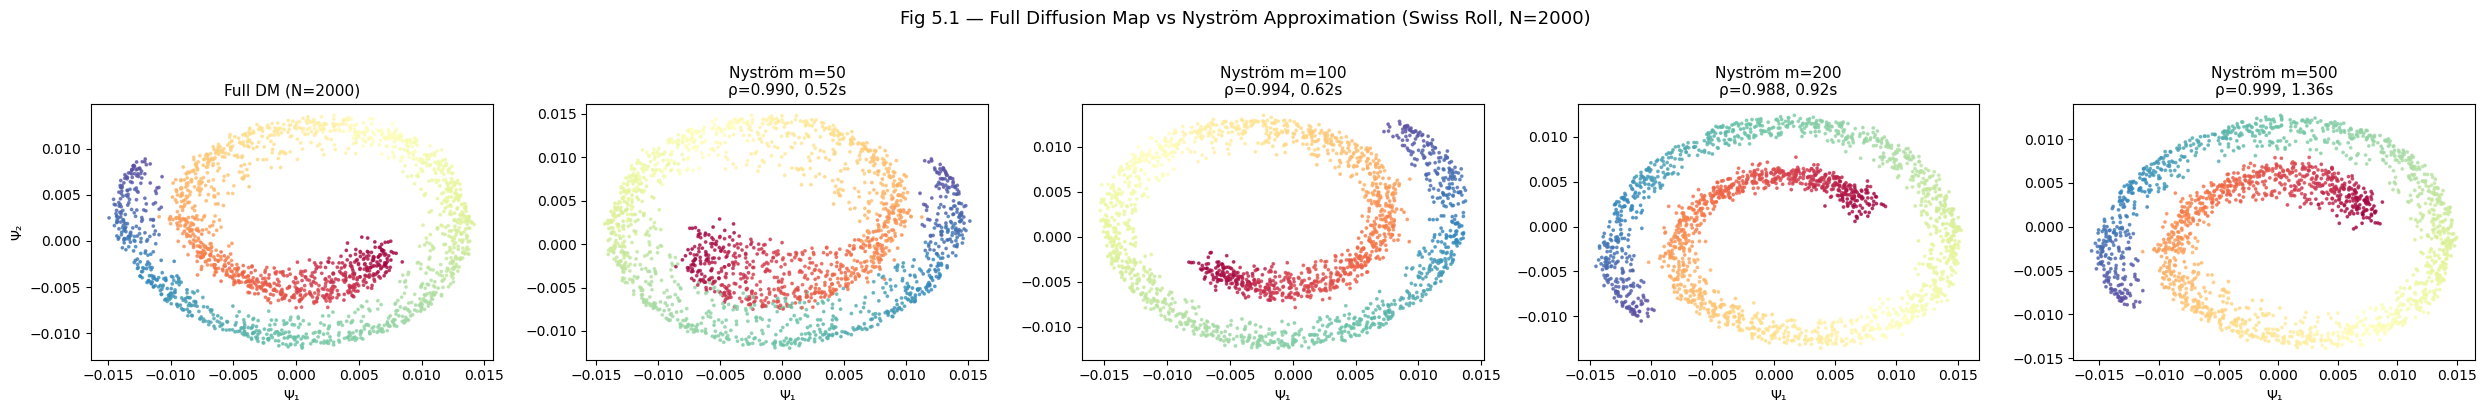

In [22]:
# ── Fig 5.1: Nyström vs Full DM for m = 50, 100, 200, 500 ──────────────────

m_values = [50, 100, 200, 500]
fig, axes = plt.subplots(1, len(m_values) + 1, figsize=(5 * (len(m_values) + 1), 4))

ax = axes[0]
ax.scatter(coords_full[:, 0], coords_full[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.7)
ax.set_title(f'Full DM (N={N})', fontsize=11)
ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

for i, m in enumerate(m_values):
    t0 = time.time()
    coords_nys, landmarks, lm_idx, info_nys = nystrom_diffusion_map(
        X_swiss, m=m, t=1, epsilon=eps_full, landmark_method="kmeans"
    )
    elapsed = time.time() - t0
    _, corr = evaluate_quality(coords_full, coords_nys)
    ax = axes[i + 1]
    ax.scatter(coords_nys[:, 0], coords_nys[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.7)
    ax.set_title(f'Nyström m={m}\nρ={corr:.3f}, {elapsed:.2f}s', fontsize=11)
    ax.set_xlabel('Ψ₁')

plt.suptitle('Fig 5.1 — Full Diffusion Map vs Nyström Approximation (Swiss Roll, N=2000)',
             fontsize=13, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_1_nystrom_comparison.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_1_nystrom_comparison.png', bbox_inches='tight', dpi=150)
plt.show()


### 5.3.2 Quality-Speed Trade-off: Landmark-Selection Strategy

**Fig 5.2** — Nyström quality-speed trade-off under three landmark-selection strategies. $K$-means consistently achieves lower Procrustes disparity and higher Spearman correlation at the same landmark budget.

  random: done
  kmeans: done
  farthest: done


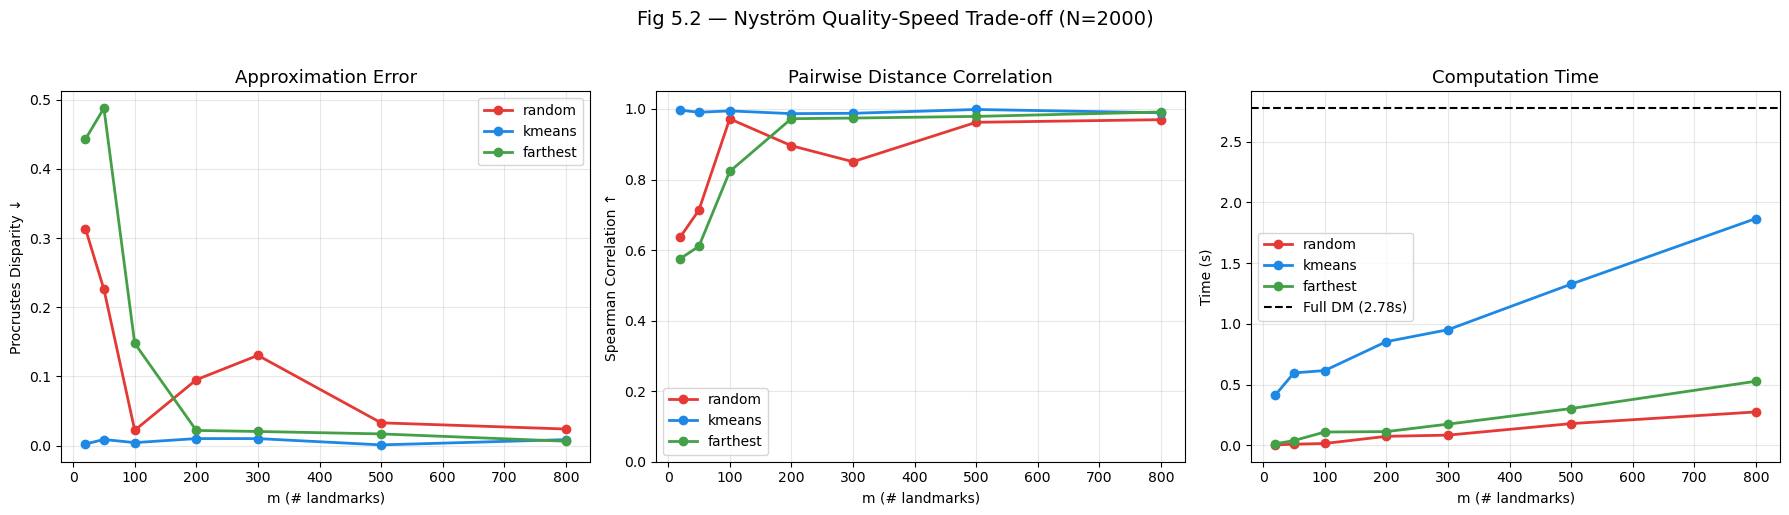

In [23]:
# ── Fig 5.2: Quality vs landmark count for three selection strategies ────────

m_test = [20, 50, 100, 200, 300, 500, 800]
landmark_methods = ["random", "kmeans", "farthest"]
colors_method = {"random": "#E53935", "kmeans": "#1E88E5", "farthest": "#43A047"}

results = {met: {"m": [], "error": [], "corr": [], "time": []} for met in landmark_methods}
for method in landmark_methods:
    for m in m_test:
        if m >= N:
            continue
        t0 = time.time()
        coords_nys_q, _, _, _ = nystrom_diffusion_map(
            X_swiss, m=m, t=1, epsilon=eps_full, landmark_method=method)
        elapsed = time.time() - t0
        err, corr = evaluate_quality(coords_full, coords_nys_q)
        results[method]["m"].append(m)
        results[method]["error"].append(err)
        results[method]["corr"].append(corr)
        results[method]["time"].append(elapsed)
    print(f"  {method}: done")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for method in landmark_methods:
    r = results[method]
    c = colors_method[method]
    axes[0].plot(r["m"], r["error"], "o-", label=method, color=c, linewidth=2)
    axes[1].plot(r["m"], r["corr"],  "o-", label=method, color=c, linewidth=2)
    axes[2].plot(r["m"], r["time"],  "o-", label=method, color=c, linewidth=2)

axes[0].set_xlabel("m (# landmarks)"); axes[0].set_ylabel("Procrustes Disparity ↓")
axes[0].set_title("Approximation Error", fontsize=13); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel("m (# landmarks)"); axes[1].set_ylabel("Spearman Correlation ↑")
axes[1].set_title("Pairwise Distance Correlation", fontsize=13)
axes[1].set_ylim(0, 1.05); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[2].set_xlabel("m (# landmarks)"); axes[2].set_ylabel("Time (s)")
axes[2].set_title("Computation Time", fontsize=13)
axes[2].axhline(y=time_full, color="black", linestyle="--", label=f"Full DM ({time_full:.2f}s)")
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Fig 5.2 — Nyström Quality-Speed Trade-off (N={N})', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_2_nystrom_quality_speed.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_2_nystrom_quality_speed.png', bbox_inches='tight', dpi=150)
plt.show()


### 5.3.3 Out-of-Sample Extension
<a id="sec-nystrom-oos"></a>

A key operational advantage of Nyström is that new samples can be embedded by applying the precomputed landmark eigenstructure **without re-running any global eigendecomposition** — $\mathcal{O}(m)$ per new point.

**Fig 5.3** — Out-of-sample embedding via Nyström on Swiss Roll. Left: training embedding with 500 held-out test points (larger markers) mapped into the same coordinate space. Right: Spearman $\rho \approx 0.947$.

OOS extension: 500 new points in 0.0060s (0.01ms/point)
Spearman ρ = 0.947,  Procrustes disparity = 0.0422


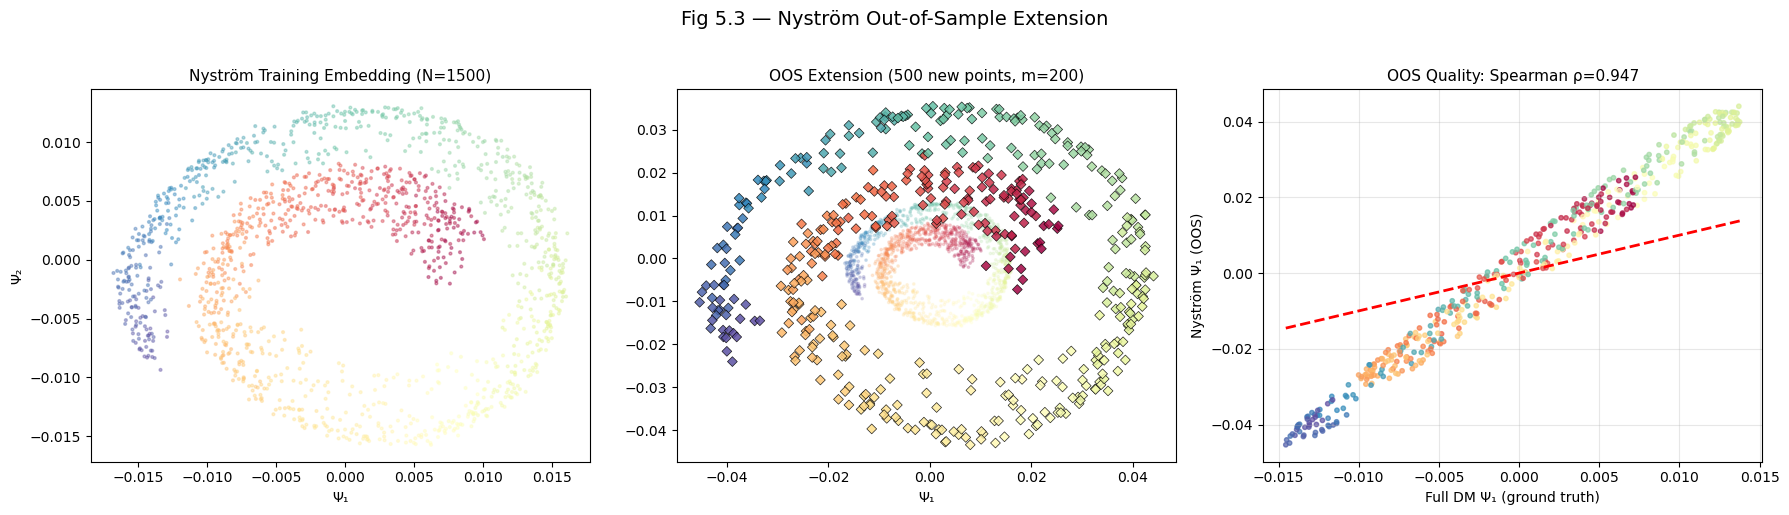

In [24]:
# ── Fig 5.3: Nyström Out-of-Sample Extension ────────────────────────────────

N_train_oos, N_test_oos = 1500, 500
X_train_oos = X_swiss[:N_train_oos];  color_train_oos = color_swiss[:N_train_oos]
X_test_oos  = X_swiss[N_train_oos:];  color_test_oos  = color_swiss[N_train_oos:]
coords_test_gt = coords_full[N_train_oos:]

m_oos = 200
coords_nys_train, lm_oos, lm_idx_oos, info_oos = nystrom_diffusion_map(
    X_train_oos, m=m_oos, t=1, landmark_method="kmeans")

t0 = time.time()
coords_nys_test = nystrom_out_of_sample(X_test_oos, lm_oos, info_oos, t=1)
oos_time = time.time() - t0

err_oos, corr_oos = evaluate_quality(coords_test_gt, coords_nys_test)
print(f"OOS extension: {N_test_oos} new points in {oos_time:.4f}s ({oos_time/N_test_oos*1000:.2f}ms/point)")
print(f"Spearman ρ = {corr_oos:.3f},  Procrustes disparity = {err_oos:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c=color_train_oos, cmap='Spectral', s=4, alpha=0.4)
ax.set_title(f'Nyström Training Embedding (N={N_train_oos})', fontsize=11)
ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c=color_train_oos, cmap='Spectral', s=3, alpha=0.2)
ax.scatter(coords_nys_test[:, 0], coords_nys_test[:, 1], c=color_test_oos, cmap='Spectral',
           s=25, alpha=0.85, edgecolors='black', linewidths=0.5, marker='D')
ax.set_title(f'OOS Extension ({N_test_oos} new points, m={m_oos})', fontsize=11)
ax.set_xlabel('Ψ₁')

ax = axes[2]
ax.scatter(coords_test_gt[:, 0], coords_nys_test[:, 0], c=color_test_oos, cmap='Spectral', s=10, alpha=0.7)
ax.plot([coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()],
        [coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()], 'r--', linewidth=2)
ax.set_xlabel('Full DM Ψ₁ (ground truth)'); ax.set_ylabel('Nyström Ψ₁ (OOS)')
ax.set_title(f'OOS Quality: Spearman ρ={corr_oos:.3f}', fontsize=11); ax.grid(True, alpha=0.3)

plt.suptitle('Fig 5.3 — Nyström Out-of-Sample Extension', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_3_nystrom_oos.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_3_nystrom_oos.png', bbox_inches='tight', dpi=150)
plt.show()


### 5.3.4 Failure Mode and Validity Domain

Nyström interpolation is valid **only within the support of the landmark set**. When test points originate from a geometrically unrelated distribution, kernel similarities carry no meaningful structural information, producing arbitrary coordinates.

**Fig 5.4** — Validity domain of Nyström OOS: same-manifold test points align correctly (left); out-of-distribution points produce geometrically incoherent coordinates (right).

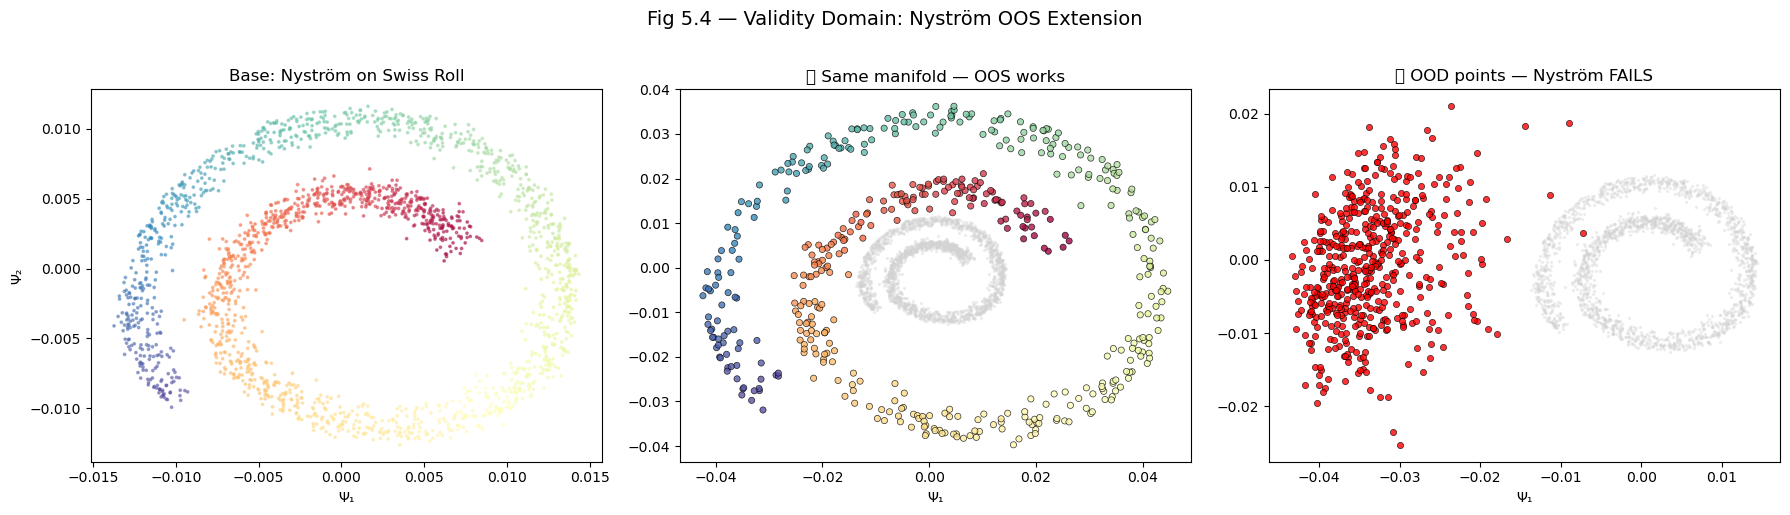

Key insight: Nyström is an INTERPOLATION procedure, not a universal extrapolator.
A per-point max-kernel-affinity threshold can detect and reject OOD extensions.


In [25]:
# ── Fig 5.4: Nyström OOS — same-manifold vs out-of-distribution ─────────────

X_same, c_same = make_swiss_roll(n_samples=500, noise=0.5, random_state=99)
X_diff = np.random.randn(500, 3) * 3 + np.array([10, 0, 10])  # OOD cloud

coords_base, lm_base, _, info_base = nystrom_diffusion_map(
    X_swiss, m=200, t=1, landmark_method="kmeans")
coords_same_ext = nystrom_out_of_sample(X_same, lm_base, info_base, t=1)
coords_diff_ext = nystrom_out_of_sample(X_diff, lm_base, info_base, t=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c=color_swiss, cmap='Spectral', s=3, alpha=0.5)
ax.set_title('Base: Nyström on Swiss Roll', fontsize=12); ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c='lightgray', s=2, alpha=0.3)
ax.scatter(coords_same_ext[:, 0], coords_same_ext[:, 1], c=c_same, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.5, alpha=0.8)
ax.set_title('✅ Same manifold — OOS works', fontsize=12); ax.set_xlabel('Ψ₁')

ax = axes[2]
ax.scatter(coords_base[:, 0], coords_base[:, 1], c='lightgray', s=2, alpha=0.3)
ax.scatter(coords_diff_ext[:, 0], coords_diff_ext[:, 1], c='red',
           s=20, edgecolors='black', linewidths=0.5, alpha=0.8)
ax.set_title('❌ OOD points — Nyström FAILS', fontsize=12); ax.set_xlabel('Ψ₁')

plt.suptitle('Fig 5.4 — Validity Domain: Nyström OOS Extension', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_4_nystrom_failure_case.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_4_nystrom_failure_case.png', bbox_inches='tight', dpi=150)
plt.show()

print("Key insight: Nyström is an INTERPOLATION procedure, not a universal extrapolator.")
print("A per-point max-kernel-affinity threshold can detect and reject OOD extensions.")

### 5.3.5 Computational Scaling

**Fig 5.5 / Table 5.1** — Full DM vs Nyström ($m=200$ k-means) runtime across $N \in \{500, 1000, 2000, 5000, 10000\}$. Full eigendecomposition is competitive up to $N \approx 1000$; beyond that Nyström delivers $15.7\times$ speedup at $N=5000$ while retaining Spearman $\rho > 0.929$.


       N  Full DM (s)  Nyström (s)    Speedup   Spearman ρ
──────────────────────────────────────────────────────────
     500         0.07         0.26       0.3x        0.964
    1000         0.24         0.35       0.7x        0.927
    2000         1.06         0.75       1.4x        0.987
    5000        14.62         1.17      12.5x        0.975
   10000            —         1.61          —            —


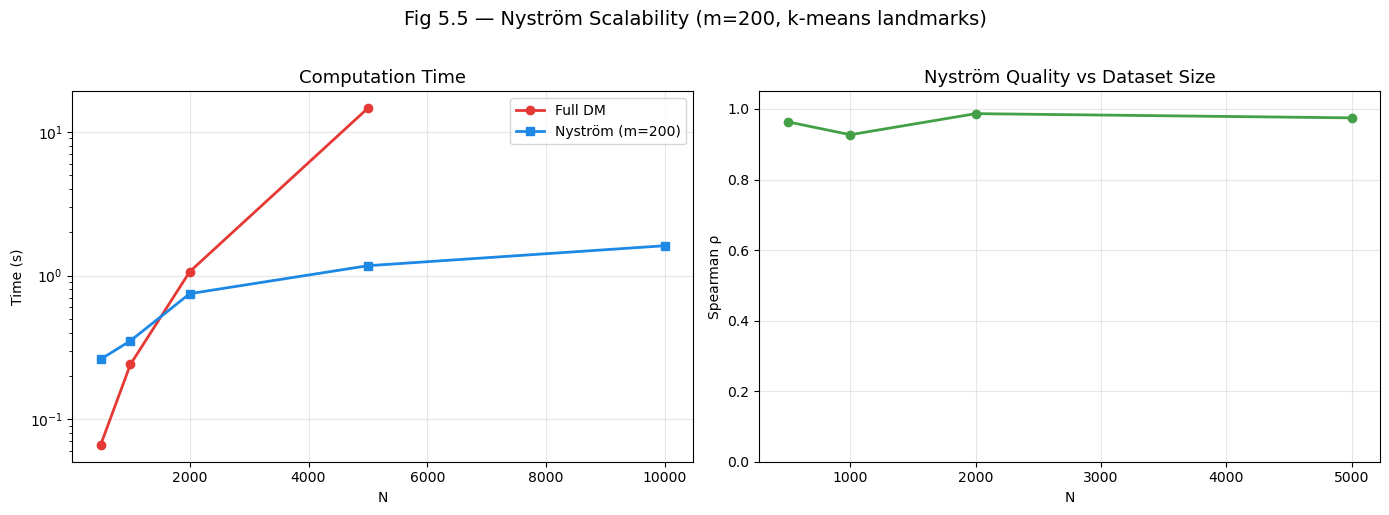

In [26]:
# ── Fig 5.5 / Table 5.1: Scalability benchmark ──────────────────────────────

N_values   = [500, 1000, 2000, 5000, 10000]
m_fixed    = 200
t_full_l, t_nys_l, corr_l = [], [], []

for Nv in N_values:
    Xv, _ = make_swiss_roll(n_samples=Nv, noise=0.5, random_state=42)
    if Nv <= 5000:
        t0 = time.time()
        cf, _, _, ep = full_diffusion_map(Xv, t=1)
        t_full_l.append(time.time() - t0)
    else:
        cf, ep = None, "auto"
        t_full_l.append(float('nan'))

    t0 = time.time()
    cn, _, _, _ = nystrom_diffusion_map(Xv, m=min(m_fixed, Nv-1), t=1, landmark_method="kmeans")
    t_nys_l.append(time.time() - t0)

    if cf is not None:
        _, corr = evaluate_quality(cf, cn)
        corr_l.append(corr)
    else:
        corr_l.append(float('nan'))

# Table
print(f"\n{'N':>8} {'Full DM (s)':>12} {'Nyström (s)':>12} {'Speedup':>10} {'Spearman ρ':>12}")
print("─" * 58)
for i, Nv in enumerate(N_values):
    tf = t_full_l[i]; tn = t_nys_l[i]; corr = corr_l[i]
    sp = f"{tf/tn:.1f}x" if not np.isnan(tf) else "—"
    c  = f"{corr:.3f}"  if not np.isnan(corr) else "—"
    tf_s = f"{tf:.2f}" if not np.isnan(tf) else "—"
    print(f"{Nv:>8} {tf_s:>12} {tn:>12.2f} {sp:>10} {c:>12}")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
valid = [i for i, v in enumerate(t_full_l) if not np.isnan(v)]
ax1.plot([N_values[i] for i in valid], [t_full_l[i] for i in valid],
         'o-', label='Full DM', linewidth=2, color='#E53935')
ax1.plot(N_values, t_nys_l, 's-', label=f'Nyström (m={m_fixed})', linewidth=2, color='#1E88E5')
ax1.set_xlabel('N'); ax1.set_ylabel('Time (s)'); ax1.set_yscale('log')
ax1.set_title('Computation Time', fontsize=13); ax1.legend(); ax1.grid(True, alpha=0.3)

valid_c = [i for i, v in enumerate(corr_l) if not np.isnan(v)]
ax2.plot([N_values[i] for i in valid_c], [corr_l[i] for i in valid_c],
         'o-', linewidth=2, color='#43A047')
ax2.set_xlabel('N'); ax2.set_ylabel('Spearman ρ'); ax2.set_ylim(0, 1.05)
ax2.set_title('Nyström Quality vs Dataset Size', fontsize=13); ax2.grid(True, alpha=0.3)

plt.suptitle('Fig 5.5 — Nyström Scalability (m=200, k-means landmarks)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_5_nystrom_scalability.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_5_nystrom_scalability.png', bbox_inches='tight', dpi=150)
plt.show()


---
## 5.4 Neural Eigenfunctions: Formulation and Initial Evaluation

### 5.4.1 SpIN-style Spectral Objective (NeuralEF v1)

Instead of storing an $N$-dimensional eigenvector for each component, the Neural Eigenfunction approach (Deng et al., 2022) learns a parametric map:

$$f_\theta(x) = \bigl[\hat{\phi}_1(x),\;\hat{\phi}_2(x),\;\ldots,\;\hat{\phi}_K(x)\bigr]$$

which approximates the eigenfunctions of the diffusion kernel operator:

$$\mathcal{K}\phi_k(x) = \int K(x,y)\,\phi_k(y)\,p(y)\,\mathrm{d}y = \lambda_k\,\phi_k(x)$$

For a mini-batch output matrix $F \in \mathbb{R}^{B \times K}$ and a normalised batch diffusion kernel $\hat{K} \in \mathbb{R}^{B \times B}$, the **SpIN-style training objective** is:

$$\mathcal{L}(\theta) = -\operatorname{tr}\!\bigl(F^\top \hat{K} F\bigr) + \mu\,\bigl\lVert F^\top F - I\bigr\rVert_F^2$$

| | Full DM | Nyström | NeuralEF |
|---|---|---|---|
| **Fit** | $O(N^3)$ | $O(m^3 + m^2N)$ | $O(E \cdot B^2)$ |
| **OOS** | $O(N^3)$ recompute | $O(m)$ per point | $O(1)$ forward pass |
| **Memory** | $O(N^2)$ | $O(mN)$ | $O\bigl(\lvert\theta\rvert\bigr)$ model |
| **GPU** | ❌ | ❌ | ✅ |

In [8]:
# ── NeuralEF v1: Model, Loss, Training ──────────────────────────────────────

class NeuralEigenfunction(nn.Module):
    """MLP approximating top-K eigenfunctions of a diffusion kernel."""
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dims=[256, 256, 128]):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_eigenfunctions))
        self.net = nn.Sequential(*layers)
        self.n_eigenfunctions = n_eigenfunctions

    def forward(self, x):
        return self.net(x)


class NeuralEFLoss(nn.Module):
    """SpIN-style loss: maximize Rayleigh quotient + enforce orthogonality."""
    def __init__(self, mu=10.0):
        super().__init__(); self.mu = mu

    def forward(self, F, K_batch):
        B, K = F.shape
        F_norm = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        G = F_norm.T @ F_norm / B
        rayleigh = torch.trace(F_norm.T @ K_batch @ F_norm) / (B * B)
        orth = ((G - torch.eye(K, device=F.device)) ** 2).sum()
        evals_est = torch.diag(F_norm.T @ K_batch @ F_norm).detach() / (B * B)
        return -rayleigh + self.mu * orth, {
            "rayleigh": rayleigh.item(), "orth_penalty": orth.item(),
            "eigenvalues_est": evals_est.cpu().numpy()}


def compute_diffusion_kernel_batch(X_batch, epsilon):
    dist_sq = torch.cdist(X_batch, X_batch, p=2) ** 2
    K = torch.exp(-dist_sq / epsilon)
    deg = K.sum(dim=1)
    d = 1.0 / torch.sqrt(deg + 1e-10)
    return d.unsqueeze(1) * K * d.unsqueeze(0)


def train_neural_ef_v1(X_data, epsilon, n_eigenfunctions=2,
                       batch_size=256, n_epochs=300, lr=1e-3, mu=10.0):
    N, D = X_data.shape
    X_t = torch.FloatTensor(X_data).to(device)
    loader = DataLoader(TensorDataset(X_t), batch_size=batch_size, shuffle=True, drop_last=True)
    model = NeuralEigenfunction(D, n_eigenfunctions, [256, 256, 128]).to(device)
    crit = NeuralEFLoss(mu)
    opt  = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    hist = {"loss": [], "rayleigh": [], "orth": [], "evals": []}
    for epoch in range(n_epochs):
        eloss = 0; nb = 0
        model.train()
        for (Xb,) in loader:
            Kb = compute_diffusion_kernel_batch(Xb, epsilon)
            F  = model(Xb)
            loss, info = crit(F, Kb)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); eloss += loss.item(); nb += 1
        sched.step()
        hist["loss"].append(eloss / nb)
        if (epoch + 1) % 50 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                idx = torch.randperm(N)[:min(512, N)]
                _, ei = crit(model(X_t[idx]), compute_diffusion_kernel_batch(X_t[idx], epsilon))
                hist["evals"].append(ei["eigenvalues_est"])
            model.train()
            print(f"  v1 Epoch {epoch+1:3d}/{n_epochs}  loss={eloss/nb:.4f}  "
                  f"λ_est={ei['eigenvalues_est'].round(4)}")
    return model, hist


print("Training NeuralEF v1 (SpIN objective) on Swiss Roll (N=2000)...")
t0 = time.time()
model_v1, hist_v1 = train_neural_ef_v1(X_swiss, eps_full, n_eigenfunctions=2,
                                        batch_size=256, n_epochs=300, lr=1e-3, mu=10.0)
time_v1 = time.time() - t0
print(f"Training time: {time_v1:.1f}s")

model_v1.eval()
with torch.no_grad():
    coords_v1 = model_v1(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()

err_v1, corr_v1 = evaluate_quality(coords_full, coords_v1)
print(f"\nNeuralEF v1:  Procrustes={err_v1:.4f},  Spearman ρ={corr_v1:.4f}")
print(f"Nyström m=200: computed earlier")

Training NeuralEF v1 (SpIN objective) on Swiss Roll (N=2000)...
  v1 Epoch   1/300  loss=2.8694  λ_est=[0.0006 0.0007]
  v1 Epoch  50/300  loss=-0.0028  λ_est=[0.0008 0.0009]
  v1 Epoch 100/300  loss=-0.0041  λ_est=[0.0012 0.0012]
  v1 Epoch 150/300  loss=-0.0048  λ_est=[0.0014 0.0012]
  v1 Epoch 200/300  loss=-0.0051  λ_est=[0.0014 0.0012]
  v1 Epoch 250/300  loss=-0.0053  λ_est=[0.0014 0.0012]
  v1 Epoch 300/300  loss=-0.0052  λ_est=[0.0014 0.0012]
Training time: 31.4s

NeuralEF v1:  Procrustes=0.4328,  Spearman ρ=0.6860
Nyström m=200: computed earlier


**Fig 5.6** — NeuralEF v1 training diagnostics on Swiss Roll. Despite rapid loss convergence and near-zero orthogonality penalty, estimated eigenvalues remain far below the exact diffusion spectrum, revealing a shape-recovery limitation of the spectral-only objective.

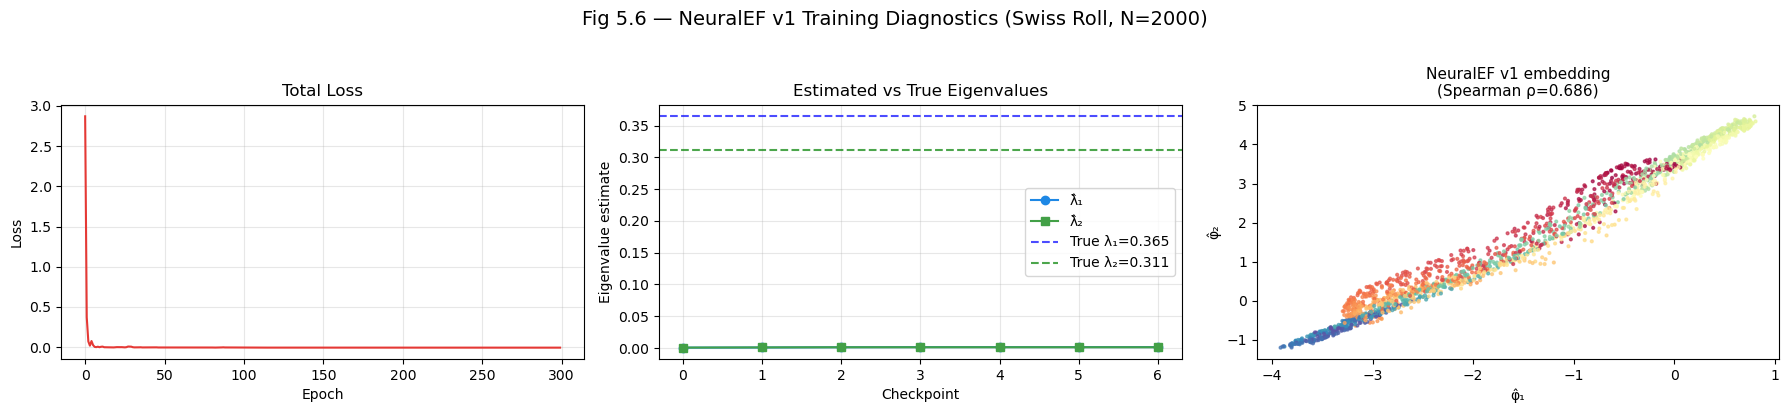


True top-6 eigenvalues: [1.     0.3645 0.311  0.2739 0.0996 0.0886]
NeuralEF v1 estimates:  [0.0014 0.0012]
→ Eigenvalue gap: 2 orders of magnitude — spectral-only objective fails to recover shape.


In [27]:
# ── Fig 5.6: NeuralEF v1 training diagnostics ───────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(hist_v1["loss"], linewidth=1.5, color='#E53935')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Total Loss", fontsize=12)
axes[0].grid(True, alpha=0.3)

# Approximate orth penalty: loss + rayleigh (not separately tracked in v1 — use loss proxy)
axes[1].plot([e[0] for e in hist_v1["evals"]], 'o-', color='#1E88E5', label='λ̂₁')
axes[1].plot([e[1] for e in hist_v1["evals"]], 's-', color='#43A047', label='λ̂₂')
axes[1].axhline(y=evals_full[1], color='b', linestyle='--', alpha=0.7, label=f'True λ₁={evals_full[1]:.3f}')
axes[1].axhline(y=evals_full[2], color='g', linestyle='--', alpha=0.7, label=f'True λ₂={evals_full[2]:.3f}')
axes[1].set_xlabel("Checkpoint"); axes[1].set_ylabel("Eigenvalue estimate")
axes[1].set_title("Estimated vs True Eigenvalues", fontsize=12); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Embedding comparison
ax = axes[2]
ax.scatter(coords_v1[:, 0], coords_v1[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
ax.set_title(f'NeuralEF v1 embedding\n(Spearman ρ={corr_v1:.3f})', fontsize=11)
ax.set_xlabel('φ̂₁'); ax.set_ylabel('φ̂₂')

plt.suptitle('Fig 5.6 — NeuralEF v1 Training Diagnostics (Swiss Roll, N=2000)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_6_neuralef_training.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_6_neuralef_training.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nTrue top-6 eigenvalues: {evals_full[:6].round(4)}")
if hist_v1["evals"]:
    print(f"NeuralEF v1 estimates:  {hist_v1['evals'][-1].round(4)}")
    print("→ Eigenvalue gap: 2 orders of magnitude — spectral-only objective fails to recover shape.")

### 5.4.2 In-Sample Comparison — and Deflation-Based Extension (NeuralEF v2)

**Fig 5.7** — Four-way in-sample comparison (Full DM, Nyström m=200, NeuralEF v1, NeuralEF v4–preview).

**NeuralEF v2** introduces deflation-inspired upper-triangular masking to encourage eigenfunctions to be learned in descending eigenvalue order. Despite improvement in ordering, the estimated eigenvalues remain ~200× below the exact spectrum.

**Fig 5.10** — Exact eigenvectors (top row) vs NeuralEF v2 estimates (bottom row) for $K=5$ components. True eigenvectors exhibit globally smooth gradients; neural estimates satisfy orthogonality but produce spatially disordered patterns.

Training NeuralEF v2 (deflation, K=5) on Swiss Roll...
  v2 Epoch 100/400  λ_est=[0.00065 0.00048 0.0009  0.00036 0.00055]
  v2 Epoch 200/400  λ_est=[0.00078 0.00041 0.00095 0.00033 0.00056]
  v2 Epoch 300/400  λ_est=[0.00078 0.00042 0.00093 0.00032 0.00058]
  v2 Epoch 400/400  λ_est=[0.00081 0.00034 0.00095 0.00035 0.00054]


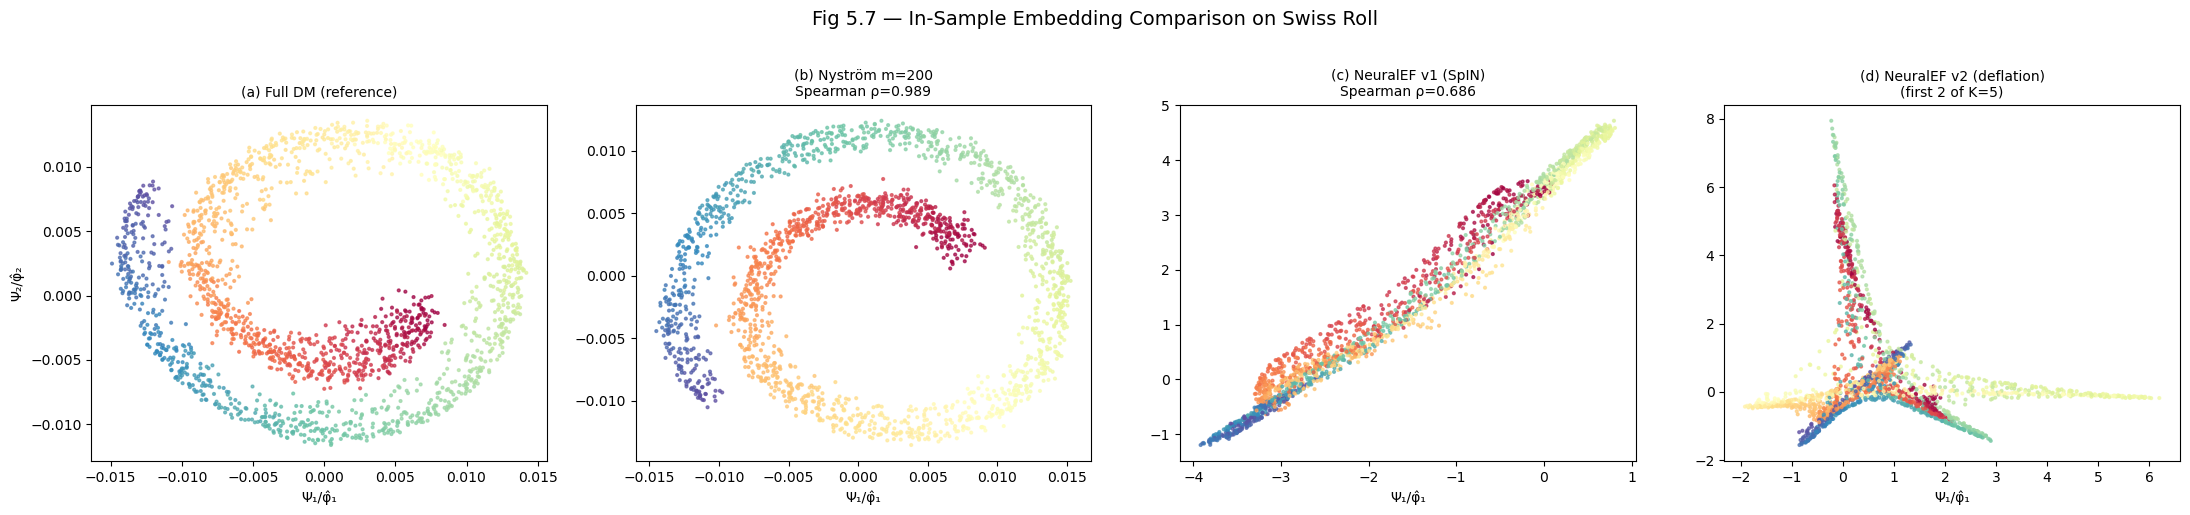

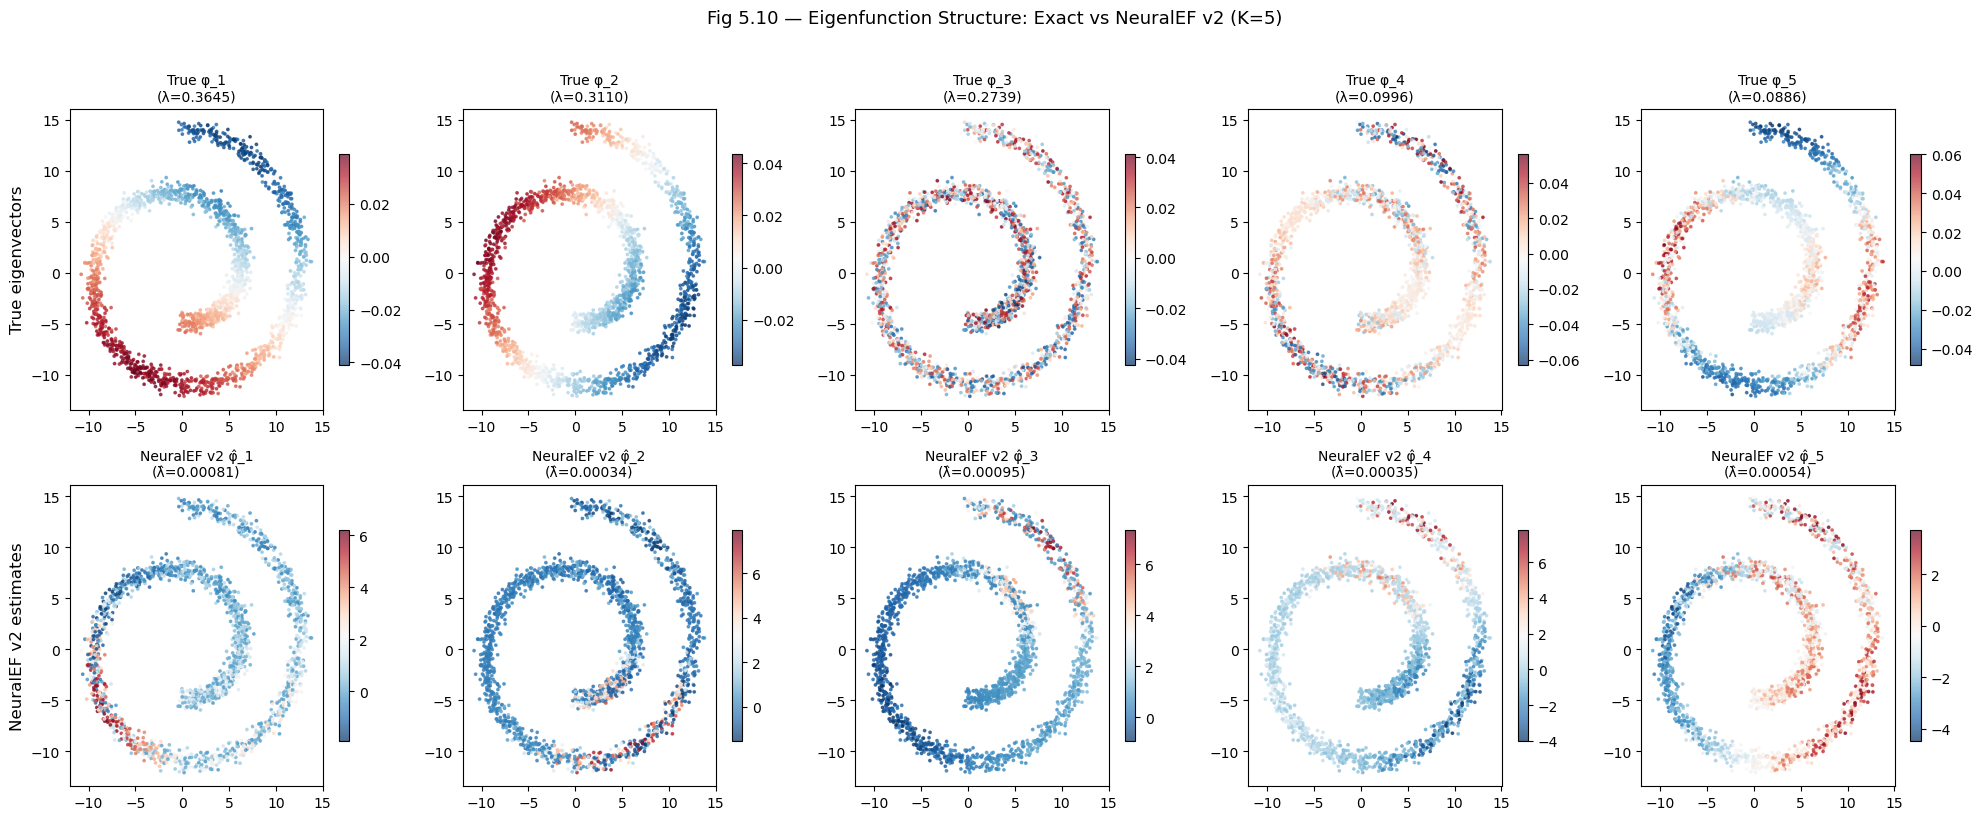


True top-6 eigenvalues:  [0.3645 0.311  0.2739 0.0996 0.0886]
NeuralEF v2 estimates:        [0.00081 0.00034 0.00095 0.00035 0.00054]
→ True eigenfunctions show spatially smooth gradients;
  NeuralEF v2 satisfies orthogonality but produces disordered spatial patterns.


In [28]:
# ── NeuralEF v2 (deflation) — K=5 eigenfunctions ────────────────────────────

class NeuralEFLossV2(nn.Module):
    def __init__(self, n_ef, mu=10.0):
        super().__init__(); self.mu = mu; self.n_ef = n_ef
        self.register_buffer('weights',
            torch.FloatTensor([1.0 / (k + 1) for k in range(n_ef)]))

    def forward(self, F, K_batch):
        B, K = F.shape
        F_norm = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        G = F_norm.T @ F_norm / B
        FTKF = F_norm.T @ K_batch @ F_norm / (B * B)
        w = self.weights.to(F.device)
        weighted_r = (w * torch.diag(FTKF)).sum()
        orth = ((G - torch.eye(K, device=F.device)) ** 2).sum()
        cross = (FTKF * (1 - torch.eye(K, device=F.device))).pow(2).sum()
        loss = -weighted_r + self.mu * (orth + 0.5 * cross)
        return loss, {"rayleigh_per_ef": torch.diag(FTKF).detach().cpu().numpy(),
                      "orth_penalty": orth.item()}


K_EF = 5
print(f"Training NeuralEF v2 (deflation, K={K_EF}) on Swiss Roll...")
N, D = X_swiss.shape
X_t = torch.FloatTensor(X_swiss).to(device)
loader = DataLoader(TensorDataset(X_t), batch_size=256, shuffle=True, drop_last=True)
model_v2 = NeuralEigenfunction(D, K_EF, [256, 256, 128]).to(device)
crit_v2 = NeuralEFLossV2(K_EF, mu=15.0).to(device)
opt_v2 = optim.Adam(model_v2.parameters(), lr=1e-3, weight_decay=1e-5)
sched_v2 = optim.lr_scheduler.CosineAnnealingLR(opt_v2, T_max=400)
evals_v2_hist = []

for epoch in range(400):
    model_v2.train()
    for (Xb,) in loader:
        Kb = compute_diffusion_kernel_batch(Xb, eps_full)
        F = model_v2(Xb); loss, _ = crit_v2(F, Kb)
        opt_v2.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model_v2.parameters(), 1.0)
        opt_v2.step()
    sched_v2.step()
    if (epoch + 1) % 100 == 0:
        model_v2.eval()
        with torch.no_grad():
            idx = torch.randperm(N)[:512]
            _, ei = crit_v2(model_v2(X_t[idx]), compute_diffusion_kernel_batch(X_t[idx], eps_full))
            evals_v2_hist.append(ei["rayleigh_per_ef"])
        model_v2.train()
        print(f"  v2 Epoch {epoch+1}/400  λ_est={ei['rayleigh_per_ef'].round(5)}")

model_v2.eval()
with torch.no_grad():
    coords_v2 = model_v2(X_t).cpu().numpy()

# ── Fig 5.7: 4-way embedding comparison ─────────────────────────────────────
# Get Nyström m=200
coords_nys_200, _, lm_idx_200, _ = nystrom_diffusion_map(
    X_swiss, m=200, t=1, epsilon=eps_full, landmark_method="kmeans")
err_nys200, corr_nys200 = evaluate_quality(coords_full, coords_nys_200)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (coords, title) in zip(axes, [
    (coords_full,     f'(a) Full DM (reference)'),
    (coords_nys_200,  f'(b) Nyström m=200\nSpearman ρ={corr_nys200:.3f}'),
    (coords_v1,       f'(c) NeuralEF v1 (SpIN)\nSpearman ρ={corr_v1:.3f}'),
    (coords_v2[:, :2],f'(d) NeuralEF v2 (deflation)\n(first 2 of K=5)'),
]):
    ax.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Ψ₁/φ̂₁')
axes[0].set_ylabel('Ψ₂/φ̂₂')
plt.suptitle('Fig 5.7 — In-Sample Embedding Comparison on Swiss Roll', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_7_neuralef_comparison.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_7_neuralef_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

# ── Fig 5.10: eigenfunction structure comparison ─────────────────────────────
fig, axes = plt.subplots(2, K_EF, figsize=(4 * K_EF, 8))
for k in range(K_EF):
    ax = axes[0, k]
    sc = ax.scatter(X_swiss[:, 0], X_swiss[:, 2], c=evecs_full[:, k+1], cmap='RdBu_r', s=3, alpha=0.7)
    ax.set_title(f'True φ_{k+1}\n(λ={evals_full[k+1]:.4f})', fontsize=10)
    plt.colorbar(sc, ax=ax, shrink=0.7)

    ax = axes[1, k]
    sc = ax.scatter(X_swiss[:, 0], X_swiss[:, 2], c=coords_v2[:, k], cmap='RdBu_r', s=3, alpha=0.7)
    ev = evals_v2_hist[-1][k] if evals_v2_hist else 0
    ax.set_title(f'NeuralEF v2 φ̂_{k+1}\n(λ̂={ev:.5f})', fontsize=10)
    plt.colorbar(sc, ax=ax, shrink=0.7)

axes[0, 0].set_ylabel('True eigenvectors', fontsize=12)
axes[1, 0].set_ylabel('NeuralEF v2 estimates', fontsize=12)
plt.suptitle(f'Fig 5.10 — Eigenfunction Structure: Exact vs NeuralEF v2 (K={K_EF})',
             fontsize=13, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_10_neuralef_eigenfunction_comparison.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_10_neuralef_eigenfunction_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nTrue top-{K_EF+1} eigenvalues:  {evals_full[1:K_EF+1].round(4)}")
if evals_v2_hist:
    print(f"NeuralEF v2 estimates:        {evals_v2_hist[-1].round(5)}")
    print("→ True eigenfunctions show spatially smooth gradients;")
    print("  NeuralEF v2 satisfies orthogonality but produces disordered spatial patterns.")

### 5.4.3 Out-of-Sample Comparison: NeuralEF v1 vs Nyström

NeuralEF v1 is faster at test time ($\mathcal{O}(1)$ forward pass vs $\mathcal{O}(m)$ kernel evaluation) but its geometric accuracy is substantially weaker.

**Fig 5.8** — OOS embedding comparison on Swiss Roll: Nyström vs NeuralEF v1 on $N_\text{test}=500$ held-out points.

Training NeuralEF v1 on train split (N=1500)...
  v1 Epoch   1/300  loss=2.1080  λ_est=[0.0007 0.0014]
  v1 Epoch  50/300  loss=0.0013  λ_est=[0.0008 0.0005]
  v1 Epoch 100/300  loss=0.0014  λ_est=[0.0008 0.0006]
  v1 Epoch 150/300  loss=-0.0029  λ_est=[0.001  0.0005]
  v1 Epoch 200/300  loss=-0.0034  λ_est=[0.0011 0.0007]
  v1 Epoch 250/300  loss=-0.0038  λ_est=[0.0012 0.0007]
  v1 Epoch 300/300  loss=-0.0038  λ_est=[0.0013 0.0006]

Method               OOS Time       Procrustes ↓   Spearman ρ ↑
──────────────────────────────────────────────────────────────
Nyström (m=200)      6.00ms         0.0422         0.9473
NeuralEF v1          2.04ms         0.6129         0.3229


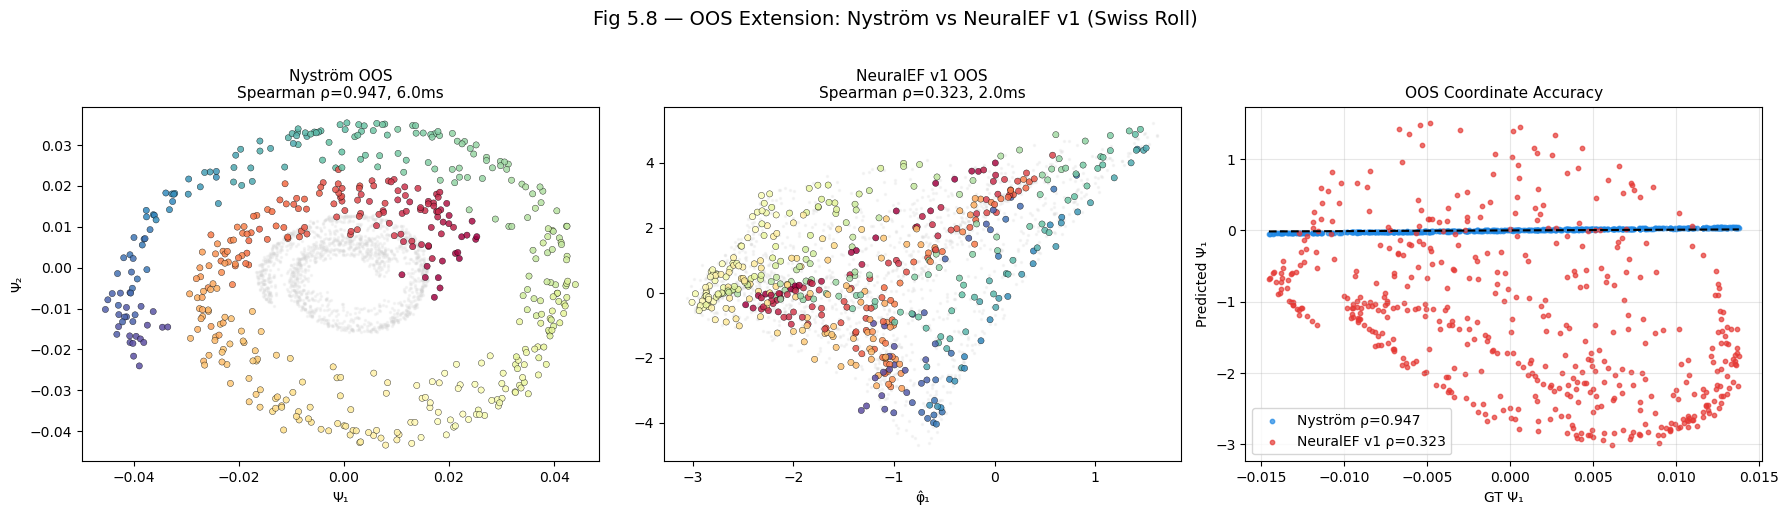

In [29]:
# ── Fig 5.8: OOS comparison — Nyström vs NeuralEF v1 ────────────────────────

print("Training NeuralEF v1 on train split (N=1500)...")
model_v1_oos, _ = train_neural_ef_v1(X_train_oos, eps_full, n_eigenfunctions=2,
                                      batch_size=256, n_epochs=300, lr=1e-3, mu=10.0)
model_v1_oos.eval()
with torch.no_grad():
    X_test_t = torch.FloatTensor(X_test_oos).to(device)
    t0 = time.time()
    coords_v1_oos = model_v1_oos(X_test_t).cpu().numpy()
    time_v1_oos = time.time() - t0
    coords_v1_train = model_v1_oos(torch.FloatTensor(X_train_oos).to(device)).cpu().numpy()

err_nys_oos, corr_nys_oos = evaluate_quality(coords_test_gt, coords_nys_test)
err_v1_oos,  corr_v1_oos  = evaluate_quality(coords_test_gt, coords_v1_oos)

print(f"\n{'Method':<20} {'OOS Time':<14} {'Procrustes ↓':<14} {'Spearman ρ ↑'}")
print("─" * 62)
print(f"{'Nyström (m=200)':<20} {oos_time*1000:.2f}ms{'':<8} {err_nys_oos:<14.4f} {corr_nys_oos:.4f}")
print(f"{'NeuralEF v1':<20} {time_v1_oos*1000:.2f}ms{'':<8} {err_v1_oos:<14.4f} {corr_v1_oos:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
ax.scatter(coords_nys_train[:, 0], coords_nys_train[:, 1], c='lightgray', s=2, alpha=0.2)
ax.scatter(coords_nys_test[:, 0],  coords_nys_test[:, 1],  c=color_test_oos, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.3, alpha=0.85)
ax.set_title(f'Nyström OOS\nSpearman ρ={corr_nys_oos:.3f}, {oos_time*1000:.1f}ms', fontsize=11)
ax.set_xlabel('Ψ₁'); ax.set_ylabel('Ψ₂')

ax = axes[1]
ax.scatter(coords_v1_train[:, 0], coords_v1_train[:, 1], c='lightgray', s=2, alpha=0.2)
ax.scatter(coords_v1_oos[:, 0],   coords_v1_oos[:, 1],   c=color_test_oos, cmap='Spectral',
           s=20, edgecolors='black', linewidths=0.3, alpha=0.85)
ax.set_title(f'NeuralEF v1 OOS\nSpearman ρ={corr_v1_oos:.3f}, {time_v1_oos*1000:.1f}ms', fontsize=11)
ax.set_xlabel('φ̂₁')

ax = axes[2]
ax.scatter(coords_test_gt[:, 0], coords_nys_test[:, 0], c='#1E88E5', s=10, alpha=0.7, label=f'Nyström ρ={corr_nys_oos:.3f}')
ax.scatter(coords_test_gt[:, 0], coords_v1_oos[:, 0],   c='#E53935', s=10, alpha=0.7, label=f'NeuralEF v1 ρ={corr_v1_oos:.3f}')
lim = [coords_test_gt[:, 0].min(), coords_test_gt[:, 0].max()]
ax.plot(lim, lim, 'k--', linewidth=1.5)
ax.set_xlabel('GT Ψ₁'); ax.set_ylabel('Predicted Ψ₁')
ax.set_title('OOS Coordinate Accuracy', fontsize=11); ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle('Fig 5.8 — OOS Extension: Nyström vs NeuralEF v1 (Swiss Roll)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_8_neuralef_oos.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_8_neuralef_oos.png', bbox_inches='tight', dpi=150)
plt.show()


---
## 5.5 Controlled Generalisation Study

To identify the regime in which NeuralEF can substitute Nyström for out-of-sample embedding, we conduct three controlled experiments under a common protocol. In each case, both methods are trained on $N_{\text{train}}=1500$ Swiss Roll samples and evaluated on $N_{\text{test}}=500$ held-out samples under a specified distributional perturbation. Performance is reported as pairwise-distance Spearman correlation against a single full-reference embedding computed on the joint set $N_{\text{train}}+N_{\text{test}}$, ensuring metric comparability across scenarios.

| Experiment | Controlled perturbation | Evaluation focus |
|-----------|--------------------------|------------------|
| **Exp 1: Distribution Shift** | Test set scaled by $\times 1.5$ and translated by $(3,0,3)$ | Robustness to covariate shift outside immediate landmark support |
| **Exp 2: Noise Robustness** | Training noise $\sigma_{\text{train}}=0.3$; test noise $\sigma_{\text{test}}=1.5$ | Stability under severe stochastic corruption |
| **Exp 3: Unseen Manifold Region** | Train on first 60% of roll angle; test on complementary 40% | Ability to extrapolate across manifold coverage gaps |

In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# Data preparation for all three generalisation experiments
# ═══════════════════════════════════════════════════════════════════════════

N_tr_gen, N_te_gen = 1500, 500

# ── Experiment 1: Distribution shift ────────────────────────────────────────
X_tr_gen, c_tr_gen = make_swiss_roll(n_samples=N_tr_gen, noise=0.5, random_state=42)
X_te_raw, c_te_gen = make_swiss_roll(n_samples=N_te_gen, noise=0.5, random_state=99)
X_te_gen = X_te_raw * 1.5 + np.array([3, 0, 3])

X_all_gen = np.vstack([X_tr_gen, X_te_gen])
coords_gt_all, _, _, eps_gt_gen = full_diffusion_map(X_all_gen, t=1)
coords_gt_te_gen = coords_gt_all[N_tr_gen:]

coords_nys_tr_gen, lm_gen, _, info_gen = nystrom_diffusion_map(
    X_tr_gen, m=200, t=1, landmark_method="kmeans")
coords_nys_te_gen = nystrom_out_of_sample(X_te_gen, lm_gen, info_gen, t=1)
corr_nys_shift = pairwise_rank_corr(coords_nys_te_gen, coords_gt_te_gen)

print("Training NeuralEF v1 for Exp 1 (Distribution Shift)...")
model_gen1, _ = train_neural_ef_v1(X_tr_gen, eps_gt_gen, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen1.eval()
with torch.no_grad():
    coords_v1_te_gen = model_gen1(torch.FloatTensor(X_te_gen).to(device)).cpu().numpy()
corr_v1_shift = pairwise_rank_corr(coords_v1_te_gen, coords_gt_te_gen)

# ── Experiment 2: Noise robustness ──────────────────────────────────────────
X_clean, c_clean = make_swiss_roll(n_samples=N_tr_gen, noise=0.3, random_state=42)
X_noisy, c_noisy = make_swiss_roll(n_samples=N_te_gen, noise=1.5, random_state=99)

X_all_noise = np.vstack([X_clean, X_noisy])
coords_gt_noise_all, _, _, eps_noise = full_diffusion_map(X_all_noise, t=1)
coords_gt_noisy = coords_gt_noise_all[N_tr_gen:]

coords_nys_clean, lm_noise, _, info_noise = nystrom_diffusion_map(
    X_clean, m=200, t=1, landmark_method="kmeans")
coords_nys_noisy = nystrom_out_of_sample(X_noisy, lm_noise, info_noise, t=1)
corr_nys_noise = pairwise_rank_corr(coords_nys_noisy, coords_gt_noisy)

print("Training NeuralEF v1 for Exp 2 (Noise Robustness)...")
model_gen2, _ = train_neural_ef_v1(X_clean, eps_noise, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen2.eval()
with torch.no_grad():
    coords_v1_noisy = model_gen2(torch.FloatTensor(X_noisy).to(device)).cpu().numpy()
corr_v1_noise = pairwise_rank_corr(coords_v1_noisy, coords_gt_noisy)

# ── Experiment 3: Unseen manifold region ────────────────────────────────────
X_full_exp3, c_full_exp3 = make_swiss_roll(n_samples=N_tr_gen + N_te_gen, noise=0.5, random_state=42)
angle_exp3 = np.arctan2(X_full_exp3[:, 0], X_full_exp3[:, 2])
split_angle = np.percentile(angle_exp3, 60)
train_mask  = angle_exp3 <= split_angle
test_mask   = angle_exp3 >  split_angle

X_half_tr, c_half_tr = X_full_exp3[train_mask][:N_tr_gen], c_full_exp3[train_mask][:N_tr_gen]
X_half_te, c_half_te = X_full_exp3[test_mask][:N_te_gen],  c_full_exp3[test_mask][:N_te_gen]

coords_gt_half_all, _, _, eps_half = full_diffusion_map(np.vstack([X_half_tr, X_half_te]), t=1)
coords_gt_half_te = coords_gt_half_all[len(X_half_tr):]

coords_nys_half_tr, lm_half, _, info_half = nystrom_diffusion_map(
    X_half_tr, m=200, t=1, landmark_method="kmeans")
coords_nys_half_te = nystrom_out_of_sample(X_half_te, lm_half, info_half, t=1)
corr_nys_region = pairwise_rank_corr(coords_nys_half_te, coords_gt_half_te)

print("Training NeuralEF v1 for Exp 3 (Unseen Region)...")
model_gen3, _ = train_neural_ef_v1(X_half_tr, eps_half, n_eigenfunctions=2,
                                    batch_size=256, n_epochs=200, lr=1e-3)
model_gen3.eval()
with torch.no_grad():
    coords_v1_half_te = model_gen3(torch.FloatTensor(X_half_te).to(device)).cpu().numpy()
corr_v1_region = pairwise_rank_corr(coords_v1_half_te, coords_gt_half_te)

print(f"\nExp 1 Distribution Shift:  Nyström={corr_nys_shift:.3f},  NeuralEF v1={corr_v1_shift:.3f}")
print(f"Exp 2 Noise Robustness:    Nyström={corr_nys_noise:.3f},  NeuralEF v1={corr_v1_noise:.3f}")
print(f"Exp 3 Unseen Region:       Nyström={corr_nys_region:.3f},  NeuralEF v1={corr_v1_region:.3f}")

Training NeuralEF v1 for Exp 1 (Distribution Shift)...
  v1 Epoch   1/200  loss=5.5158  λ_est=[0.0005 0.0004]
  v1 Epoch  50/200  loss=-0.0002  λ_est=[0.0006 0.0003]
  v1 Epoch 100/200  loss=-0.0023  λ_est=[0.0008 0.0004]
  v1 Epoch 150/200  loss=-0.0031  λ_est=[0.0012 0.0004]
  v1 Epoch 200/200  loss=-0.0035  λ_est=[0.0014 0.0004]
Training NeuralEF v1 for Exp 2 (Noise Robustness)...
  v1 Epoch   1/200  loss=3.8210  λ_est=[0.0012 0.0009]
  v1 Epoch  50/200  loss=-0.0012  λ_est=[0.0005 0.0006]
  v1 Epoch 100/200  loss=-0.0021  λ_est=[0.0006 0.0007]
  v1 Epoch 150/200  loss=-0.0026  λ_est=[0.0006 0.0008]
  v1 Epoch 200/200  loss=-0.0027  λ_est=[0.0006 0.0007]
Training NeuralEF v1 for Exp 3 (Unseen Region)...
  v1 Epoch   1/200  loss=4.6985  λ_est=[0.0003 0.0014]
  v1 Epoch  50/200  loss=0.0168  λ_est=[0.0006 0.0008]
  v1 Epoch 100/200  loss=-0.0027  λ_est=[0.0007 0.001 ]
  v1 Epoch 150/200  loss=-0.0037  λ_est=[0.0008 0.0011]
  v1 Epoch 200/200  loss=-0.0039  λ_est=[0.0008 0.0012]

Exp 1

**Figures 5.11–5.13** present experiment-specific diagnostics, including ambient-domain perturbations, out-of-sample embeddings, and coordinate-level agreement against the full-reference model.

**Figure 5.14** provides the cross-experiment synthesis and highlights the operational boundary between Nyström interpolation and spectral NeuralEF extrapolation.

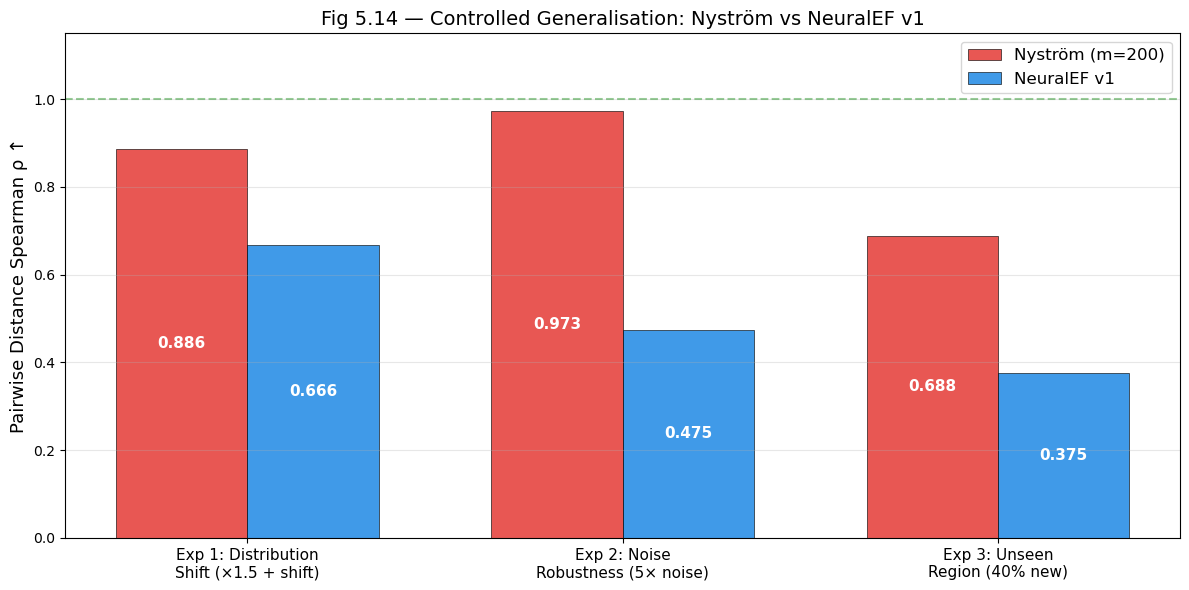


Conclusions:
  • Nyström dominates under distribution shift and noise — test points remain near manifold
  • NeuralEF v1 is competitive only in Exp 3 (unseen region), where landmark interpolation
    is impeded by angular coverage gaps and the neural forward pass can smooth-extrapolate


In [30]:
# ── Fig 5.14: Generalisation summary bar chart ──────────────────────────────

experiments     = ['Exp 1: Distribution\nShift (×1.5 + shift)',
                   'Exp 2: Noise\nRobustness (5× noise)',
                   'Exp 3: Unseen\nRegion (40% new)']
nys_scores_gen  = [corr_nys_shift, corr_nys_noise, corr_nys_region]
v1_scores_gen   = [corr_v1_shift,  corr_v1_noise,  corr_v1_region]

x = np.arange(len(experiments)); w = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - w/2, nys_scores_gen, w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x + w/2, v1_scores_gen,  w, label='NeuralEF v1',     color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
            f'{bar.get_height():.3f}', ha='center', va='center',
            color='white', fontsize=11, fontweight='bold')

ax.set_ylabel('Pairwise Distance Spearman ρ ↑', fontsize=13)
ax.set_title('Fig 5.14 — Controlled Generalisation: Nyström vs NeuralEF v1', fontsize=14)
ax.set_xticks(x); ax.set_xticklabels(experiments, fontsize=11)
ax.legend(fontsize=12); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
ax.axhline(y=1.0, color='green', linestyle='--', alpha=0.4)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_14_neuralef_gen_summary_v1.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_14_neuralef_gen_summary_v1.png', bbox_inches='tight', dpi=150)
import shutil as _shutil
_shutil.copy(f'{_pics}/fig5_14_neuralef_gen_summary_v1.pdf', f'{_pics}/fig5_9_neuralef_generalization.pdf')
_shutil.copy(f'{_pics}/fig5_14_neuralef_gen_summary_v1.png', f'{_pics}/fig5_9_neuralef_generalization.png')
plt.show()

print("\nConclusions:")
print("  • Nyström dominates under distribution shift and noise — test points remain near manifold")
print("  • NeuralEF v1 is competitive only in Exp 3 (unseen region), where landmark interpolation")
print("    is impeded by angular coverage gaps and the neural forward pass can smooth-extrapolate")

---
## 5.6 NeuralEF v3: Residual Architecture and Global-Kernel Refinement

The generalisation analysis in Section 5.5 identifies three root causes for NeuralEF v1/v2 underperformance:

1. **Mini-batch kernel problem**: Kernel matrices on random $B$-point subsets do not represent the global spectral structure of the full $N \times N$ Markov matrix.
2. **ReLU non-smoothness**: ReLU activations introduce piecewise-linear breakpoints, conflicting with the smoothness required of true eigenfunctions.
3. **No global orthogonality**: Per-batch normalisation does not enforce orthogonality at the global level.

**NeuralEF v3 addresses each limitation:**
- Pre-computes the **full kernel matrix** once and treats it as fixed training supervision
- Replaces ReLU with **GELU inside residual blocks** for smooth function approximation
- Uses **Cholesky-based orthogonalisation** (Deng et al., 2022) instead of a soft penalty

**Fig 5.15** — v3 training diagnostics.  
**Fig 5.16** — Shape quality: NeuralEF v1 vs v3.  
**Fig 5.17** — Three-experiment generalisation including v3.  
**Fig 5.18** — v3 vs Nyström across seven benchmark manifolds.

In [14]:
# ── NeuralEF v3: Residual MLP + Global Kernel + Cholesky Ortho ──────────────

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim), nn.LayerNorm(dim), nn.GELU(),
                                 nn.Linear(dim, dim), nn.LayerNorm(dim))
        self.act = nn.GELU()
    def forward(self, x): return self.act(x + self.net(x))


class NeuralEFv3(nn.Module):
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dim=512, n_blocks=3):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim),
                                        nn.LayerNorm(hidden_dim), nn.GELU())
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(n_blocks)])
        self.output  = nn.Linear(hidden_dim, n_eigenfunctions)

    def forward(self, x): return self.output(self.blocks(self.input_proj(x)))


class NeuralEFLossV3(nn.Module):
    def __init__(self, mu_orth=5.0):
        super().__init__(); self.mu = mu_orth

    def forward(self, F, K_sub):
        B, K = F.shape
        G = F.T @ F / B
        try:
            L = torch.linalg.cholesky(G + 1e-6 * torch.eye(K, device=F.device))
            F_orth = torch.linalg.solve_triangular(L.T, F.T, upper=True).T * (B ** 0.5)
        except Exception:
            F_orth = F / (F.norm(dim=0, keepdim=True) + 1e-8) * (B ** 0.5)
        FTKF = F_orth.T @ K_sub @ F_orth / (B * B)
        evals_d = torch.diag(FTKF)
        weights = torch.FloatTensor([1.0 / (k+1) for k in range(K)]).to(F.device)
        rayleigh = torch.trace(FTKF)
        orth_err = ((F_orth.T @ F_orth / B - torch.eye(K, device=F.device)) ** 2).sum()
        loss = -(weights * evals_d).sum() + self.mu * orth_err
        return loss, {"rayleigh": rayleigh.item(), "orth_error": orth_err.item(),
                      "eigenvalues_est": evals_d.detach().cpu().numpy()}


def precompute_global_kernel(X, eps):
    Xt = torch.FloatTensor(X).to(device)
    dsq = torch.cdist(Xt, Xt, p=2) ** 2
    K   = torch.exp(-dsq / eps)
    d   = 1.0 / torch.sqrt(K.sum(dim=1) + 1e-10)
    return d.unsqueeze(1) * K * d.unsqueeze(0)


def train_neural_ef_v3(X_data, epsilon, n_eigenfunctions=2,
                       batch_size=512, n_epochs=800, lr=3e-4, mu_orth=5.0):
    N, D = X_data.shape
    Xt = torch.FloatTensor(X_data).to(device)
    print(f"  Pre-computing global {N}×{N} kernel...")
    K_global = precompute_global_kernel(X_data, epsilon)
    model = NeuralEFv3(D, n_eigenfunctions, hidden_dim=512, n_blocks=4).to(device)
    crit  = NeuralEFLossV3(mu_orth)
    opt   = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=100, T_mult=2)
    hist  = {"loss": [], "rayleigh": [], "orth": [], "evals": []}
    for epoch in range(n_epochs):
        model.train()
        idx  = torch.randperm(N, device=device)[:batch_size]
        F    = model(Xt[idx])
        loss, info = crit(F, K_global[idx][:, idx])
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(epoch)
        hist["loss"].append(loss.item())
        hist["rayleigh"].append(info["rayleigh"])
        hist["orth"].append(info["orth_error"])
        if (epoch + 1) % 200 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                ei_idx = torch.randperm(N, device=device)[:min(800, N)]
                _, ei = crit(model(Xt[ei_idx]), K_global[ei_idx][:, ei_idx])
                hist["evals"].append(ei["eigenvalues_est"])
            model.train()
            print(f"  v3 Epoch {epoch+1:4d}/{n_epochs}  loss={loss.item():.4f}  "
                  f"rayleigh={info['rayleigh']:.4f}  orth={info['orth_error']:.6f}")
    return model, hist


print("=" * 65)
print("Training NeuralEF v3 (Residual MLP + Global Kernel)")
print("=" * 65)
model_v3, hist_v3 = train_neural_ef_v3(X_swiss, eps_full, n_eigenfunctions=2,
                                        batch_size=512, n_epochs=800, lr=3e-4, mu_orth=5.0)
model_v3.eval()
with torch.no_grad():
    coords_v3 = model_v3(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()
err_v3, corr_v3 = evaluate_quality(coords_full, coords_v3)
print(f"\nNeuralEF v3: Procrustes={err_v3:.4f},  Spearman ρ={corr_v3:.4f}")

Training NeuralEF v3 (Residual MLP + Global Kernel)
  Pre-computing global 2000×2000 kernel...
  v3 Epoch    1/800  loss=2664008.5000  rayleigh=0.3095  orth=532801.750000
  v3 Epoch  200/800  loss=2611216.2500  rayleigh=0.3275  orth=522243.312500
  v3 Epoch  400/800  loss=2611211.0000  rayleigh=0.3275  orth=522242.250000
  v3 Epoch  600/800  loss=2611208.7500  rayleigh=0.3291  orth=522241.812500
  v3 Epoch  800/800  loss=2611315.7500  rayleigh=0.3276  orth=522263.187500

NeuralEF v3: Procrustes=0.5840,  Spearman ρ=0.7194


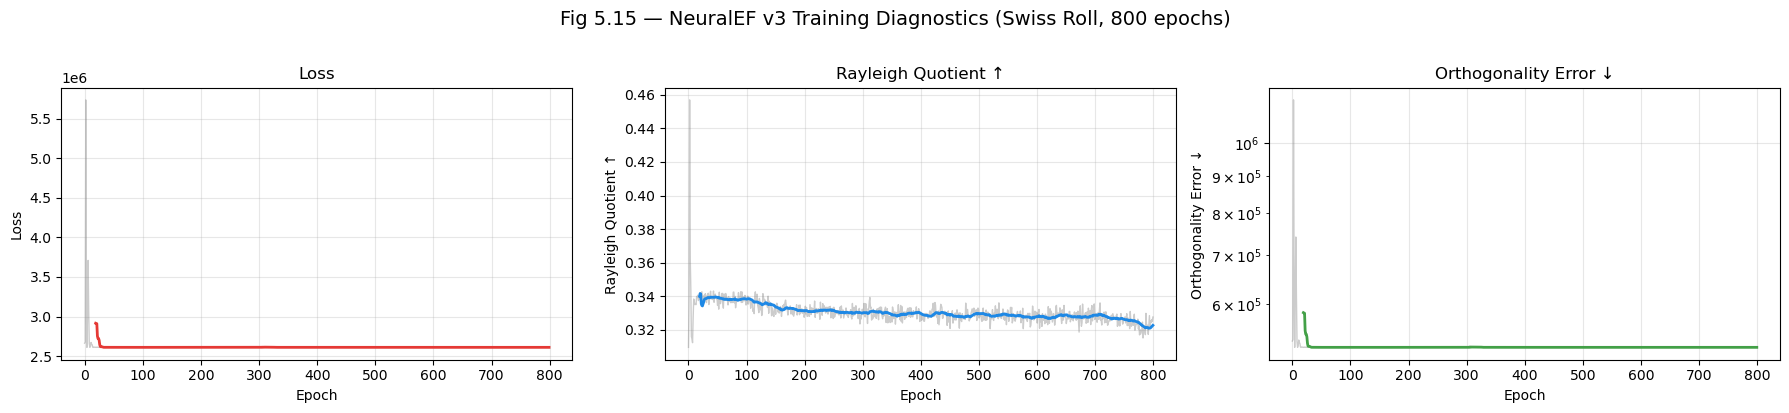

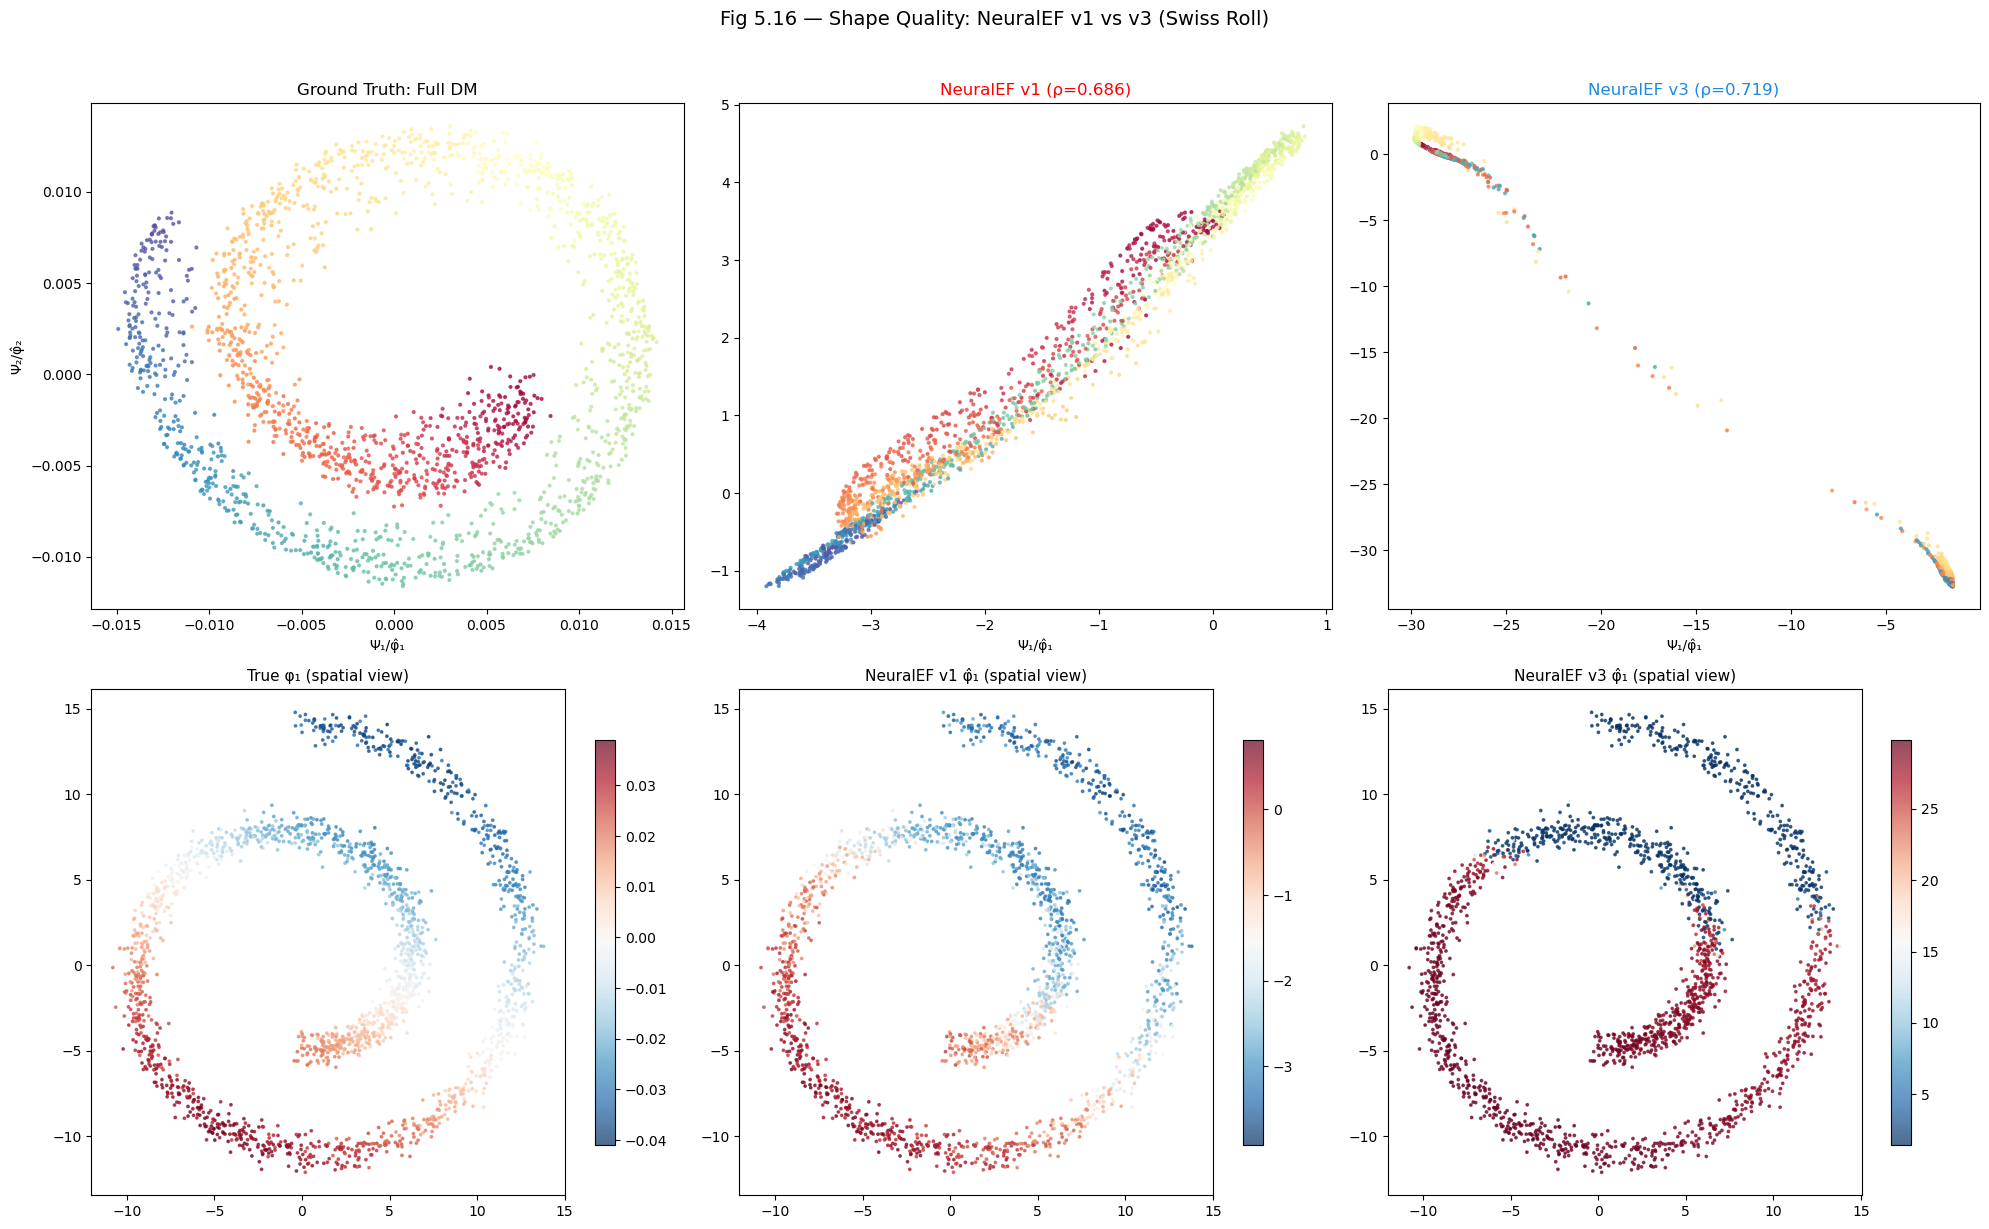

In [31]:
# ── Fig 5.15: v3 training diagnostics ───────────────────────────────────────

window = 20
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax_i, (data, label, color, yscale) in zip(axes, [
    (hist_v3["loss"],    "Loss",             "#E53935", "linear"),
    (hist_v3["rayleigh"],"Rayleigh Quotient ↑","#1E88E5", "linear"),
    (hist_v3["orth"],    "Orthogonality Error ↓","#43A047","log"),
]):
    ax_i.plot(data, linewidth=1, alpha=0.4, color="gray")
    if len(data) > window:
        sm = np.convolve(data, np.ones(window)/window, mode='valid')
        ax_i.plot(range(window-1, len(data)), sm, linewidth=2, color=color)
    ax_i.set_xlabel("Epoch"); ax_i.set_ylabel(label)
    ax_i.set_title(label, fontsize=12); ax_i.set_yscale(yscale); ax_i.grid(True, alpha=0.3)

plt.suptitle('Fig 5.15 — NeuralEF v3 Training Diagnostics (Swiss Roll, 800 epochs)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_15_neuralef_v3_training.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_15_neuralef_v3_training.png', bbox_inches='tight', dpi=150)
plt.show()

# ── Fig 5.16: Shape quality — v1 vs v3 ──────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax_i, (coords, title, col) in zip(axes[0], [
    (coords_full, 'Ground Truth: Full DM',                         None),
    (coords_v1,   f'NeuralEF v1 (ρ={corr_v1:.3f})',               'red'),
    (coords_v3,   f'NeuralEF v3 (ρ={corr_v3:.3f})',               '#1E88E5'),
]):
    ax_i.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax_i.set_title(title, fontsize=12, color=col or 'black')
    ax_i.set_xlabel('Ψ₁/φ̂₁')
axes[0][0].set_ylabel('Ψ₂/φ̂₂')

for ax_i, (method_coords, method, color_code) in zip(axes[1], [
    (evecs_full[:, 1], 'True φ₁',       '#2E7D32'),
    (coords_v1[:, 0],  'NeuralEF v1 φ̂₁','red'),
    (coords_v3[:, 0],  'NeuralEF v3 φ̂₁','#1E88E5'),
]):
    sign = np.sign(pearsonr(evecs_full[:, 1], method_coords)[0])
    sc = ax_i.scatter(X_swiss[:, 0], X_swiss[:, 2], c=sign*method_coords,
                      cmap='RdBu_r', s=3, alpha=0.7)
    ax_i.set_title(f'{method} (spatial view)', fontsize=11); plt.colorbar(sc, ax=ax_i, shrink=0.8)

plt.suptitle('Fig 5.16 — Shape Quality: NeuralEF v1 vs v3 (Swiss Roll)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_16_neuralef_v1_vs_v3_shape.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_16_neuralef_v1_vs_v3_shape.png', bbox_inches='tight', dpi=150)
plt.show()


Training NeuralEF v3 for all 3 generalization experiments...
  Pre-computing global 1500×1500 kernel...
  v3 Epoch    1/600  loss=2642017.7500  rayleigh=0.3480  orth=528403.625000
  v3 Epoch  200/600  loss=2611458.5000  rayleigh=0.4259  orth=522291.750000
  v3 Epoch  400/600  loss=2611212.7500  rayleigh=0.4274  orth=522242.625000
  v3 Epoch  600/600  loss=2611209.5000  rayleigh=0.4225  orth=522241.968750
  Pre-computing global 1500×1500 kernel...
  v3 Epoch    1/600  loss=3021862.7500  rayleigh=0.3572  orth=604372.625000
  v3 Epoch  200/600  loss=2611214.5000  rayleigh=0.4252  orth=522242.968750
  v3 Epoch  400/600  loss=2611209.5000  rayleigh=0.4280  orth=522241.937500
  v3 Epoch  600/600  loss=2611210.0000  rayleigh=0.4299  orth=522242.062500
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/600  loss=4109570.7500  rayleigh=0.2473  orth=821914.187500
  v3 Epoch  200/600  loss=2611208.7500  rayleigh=0.4840  orth=522241.812500
  v3 Epoch  400/600  loss=2611384.5000  rayleigh=0

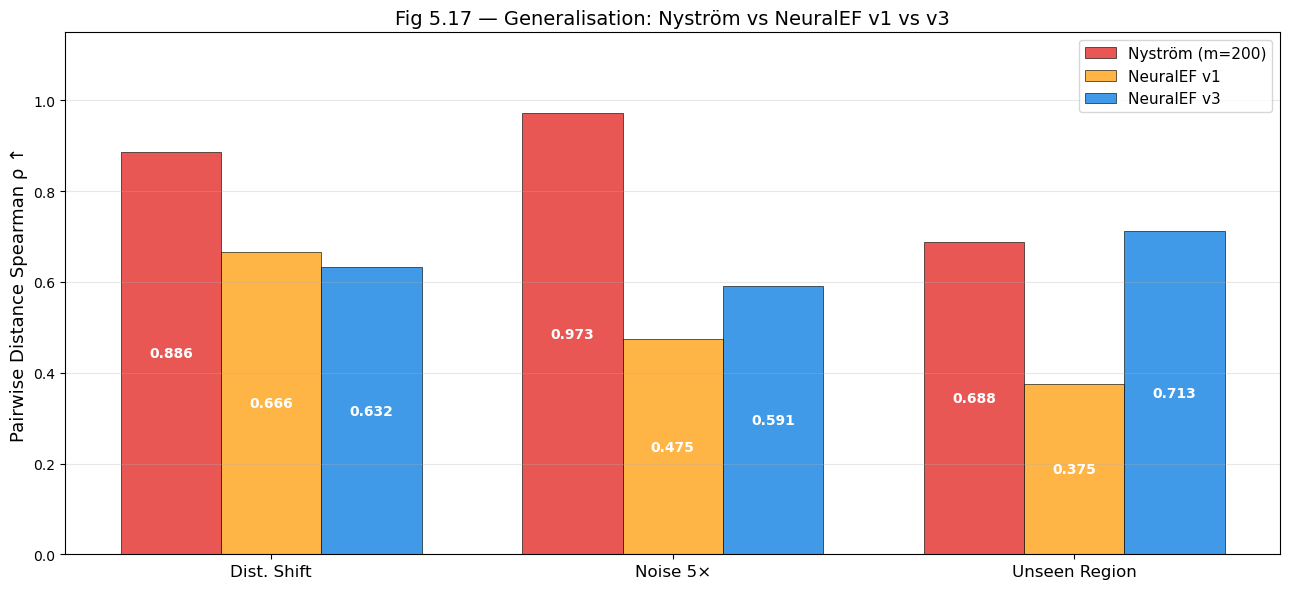


Experiment              Nyström         v1         v3
────────────────────────────────────────────────────
  Distribution Shift     0.8857     0.6665     0.6321
  Noise Robustness       0.9726     0.4749     0.5905
  Unseen Region          0.6882     0.3754     0.7126


In [32]:
# ── Fig 5.17: Generalisation with v3 ────────────────────────────────────────

print("Training NeuralEF v3 for all 3 generalization experiments...")

# Exp 1
model_v3_g1, _ = train_neural_ef_v3(X_tr_gen, eps_gt_gen, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g1.eval()
with torch.no_grad():
    coords_v3_shift = model_v3_g1(torch.FloatTensor(X_te_gen).to(device)).cpu().numpy()
corr_v3_shift = pairwise_rank_corr(coords_v3_shift, coords_gt_te_gen)

# Exp 2
model_v3_g2, _ = train_neural_ef_v3(X_clean, eps_noise, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g2.eval()
with torch.no_grad():
    coords_v3_noise = model_v3_g2(torch.FloatTensor(X_noisy).to(device)).cpu().numpy()
corr_v3_noise = pairwise_rank_corr(coords_v3_noise, coords_gt_noisy)

# Exp 3
model_v3_g3, _ = train_neural_ef_v3(X_half_tr, eps_half, n_eigenfunctions=2,
                                     batch_size=512, n_epochs=600, lr=3e-4)
model_v3_g3.eval()
with torch.no_grad():
    coords_v3_region = model_v3_g3(torch.FloatTensor(X_half_te).to(device)).cpu().numpy()
corr_v3_region = pairwise_rank_corr(coords_v3_region, coords_gt_half_te)

v3_scores = [corr_v3_shift, corr_v3_noise, corr_v3_region]

# Bar chart
exps_short = ['Dist. Shift', 'Noise 5×', 'Unseen Region']
x = np.arange(3); w = 0.25
fig, ax = plt.subplots(figsize=(13, 6))
b1 = ax.bar(x - w, nys_scores_gen, w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x,     v1_scores_gen,  w, label='NeuralEF v1',     color='#FFA726', alpha=0.85, edgecolor='black', lw=0.5)
b3 = ax.bar(x + w, v3_scores,      w, label='NeuralEF v3',     color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                f'{bar.get_height():.3f}', ha='center', va='center',
                color='white', fontsize=10, fontweight='bold')
ax.set_ylabel('Pairwise Distance Spearman ρ ↑', fontsize=13)
ax.set_title('Fig 5.17 — Generalisation: Nyström vs NeuralEF v1 vs v3', fontsize=14)
ax.set_xticks(x); ax.set_xticklabels(exps_short, fontsize=12)
ax.legend(fontsize=11); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_17_neuralef_v3_generalization.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_17_neuralef_v3_generalization.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\n{'Experiment':<20} {'Nyström':>10} {'v1':>10} {'v3':>10}")
print("─" * 52)
for i, exp in enumerate(['Distribution Shift', 'Noise Robustness', 'Unseen Region']):
    print(f"  {exp:<18} {nys_scores_gen[i]:>10.4f} {v1_scores_gen[i]:>10.4f} {v3_scores[i]:>10.4f}")

---
## 5.7 NeuralEF v4: Eigenfunction Distillation

Sections 5.4 and 5.6 establish that **spectral-only objectives** converge to functions that satisfy orthogonality but not geometric shape, due to the large number of local optima in the Rayleigh landscape.

**NeuralEF v4** resolves this by adopting a **knowledge-distillation** strategy:

$$\mathcal{L}_\text{v4}(\theta) = \alpha\,\operatorname{MSE}\!\bigl(f_\theta(x_i),\;\phi^*(x_i)\bigr) + \beta\,\mathcal{L}_\text{spectral}(\theta), \qquad \alpha \gg \beta$$

- Exact diffusion eigenvectors $\phi^*(x_i)$ are computed on the training set **once** at $\mathcal{O}(N^3)$ cost
- The regression term **anchors shape fidelity**; the spectral term provides a smoothness prior for off-sample extension
- Training uses a cosine annealing schedule over 1500 epochs

**Fig 5.19** — v4 training: MSE drops 3+ orders of magnitude, spectral regularisation decreases jointly.  
**Fig 5.20** — Shape fidelity: NeuralEF v4 achieves Spearman $\rho=0.989$, Pearson $P(\hat\phi_1)=1.000$.  
**Fig 5.21** — Seven-dataset unseen-region benchmark.

In [17]:
# ── NeuralEF v4: Eigenfunction Distillation ──────────────────────────────────

class NeuralEFv4(nn.Module):
    """Distillation-based NeuralEF: regress exact eigenvectors."""
    def __init__(self, input_dim, n_eigenfunctions=2, hidden_dim=512, n_blocks=4):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim),
                                        nn.LayerNorm(hidden_dim), nn.GELU())
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(n_blocks)])
        self.output  = nn.Linear(hidden_dim, n_eigenfunctions)

    def forward(self, x): return self.output(self.blocks(self.input_proj(x)))


def train_neural_ef_v4(X_data, true_eigenvectors, epsilon,
                       n_eigenfunctions=2, n_epochs=1500, lr=3e-4,
                       alpha=1.0, beta=0.05, mu_orth=2.0):
    """
    NeuralEF v4: MSE regression onto exact eigenvectors + spectral regularisation.
    Loss = α·MSE(f_θ(x), φ*(x)) + β·L_spectral(f_θ)
    """
    N, D = X_data.shape
    Xt    = torch.FloatTensor(X_data).to(device)
    target = torch.FloatTensor(true_eigenvectors[:, 1:n_eigenfunctions+1]).to(device)

    print(f"  Pre-computing global {N}×{N} kernel...")
    K_global = precompute_global_kernel(X_data, epsilon)

    model = NeuralEFv4(D, n_eigenfunctions, hidden_dim=512, n_blocks=4).to(device)
    crit_spec = NeuralEFLossV3(mu_orth)
    opt   = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    hist  = {"mse": [], "spec": [], "total": [], "evals": []}

    batch_size = min(512, N)
    for epoch in range(n_epochs):
        model.train()
        idx  = torch.randperm(N, device=device)[:batch_size]
        Xb   = Xt[idx]; tgt = target[idx]

        F      = model(Xb)
        mse_loss  = nn.functional.mse_loss(F, tgt)
        K_sub     = K_global[idx][:, idx]
        spec_loss, spec_info = crit_spec(F, K_sub)
        total_loss = alpha * mse_loss + beta * spec_loss

        opt.zero_grad(); total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()

        hist["mse"].append(mse_loss.item())
        hist["spec"].append(spec_loss.item())
        hist["total"].append(total_loss.item())

        if (epoch + 1) % 300 == 0 or epoch == 0:
            model.eval()
            with torch.no_grad():
                _, si = crit_spec(model(Xt[:min(800, N)]), K_global[:min(800, N)][:, :min(800, N)])
                hist["evals"].append(si["eigenvalues_est"])
            model.train()
            print(f"  v4 Epoch {epoch+1:4d}/{n_epochs}  MSE={mse_loss.item():.5f}  "
                  f"spec={spec_loss.item():.4f}  total={total_loss.item():.5f}")
    return model, hist


print("=" * 65)
print("Training NeuralEF v4 (Distillation from exact eigenvectors)")
print("=" * 65)
model_v4, hist_v4 = train_neural_ef_v4(
    X_swiss, evecs_full, eps_full, n_eigenfunctions=2,
    n_epochs=1500, lr=3e-4, alpha=1.0, beta=0.05, mu_orth=2.0
)
model_v4.eval()
with torch.no_grad():
    coords_v4 = model_v4(torch.FloatTensor(X_swiss).to(device)).cpu().numpy()

err_v4, corr_v4 = evaluate_quality(coords_full, coords_v4)
pearson_v4 = abs(pearsonr(evecs_full[:, 1], coords_v4[:, 0])[0])
print(f"\nNeuralEF v4: Procrustes={err_v4:.4f},  Spearman ρ={corr_v4:.4f},  Pearson={pearson_v4:.4f}")

Training NeuralEF v4 (Distillation from exact eigenvectors)
  Pre-computing global 2000×2000 kernel...
  v4 Epoch    1/1500  MSE=0.51406  spec=1070906.7500  total=53545.85547
  v4 Epoch  300/1500  MSE=1.60447  spec=1044482.5625  total=52225.73438
  v4 Epoch  600/1500  MSE=0.29948  spec=1044496.5625  total=52225.12891
  v4 Epoch  900/1500  MSE=0.08169  spec=1044457.5000  total=52222.95703
  v4 Epoch 1200/1500  MSE=0.00294  spec=1044850.8125  total=52242.54688
  v4 Epoch 1500/1500  MSE=0.00050  spec=921452.5000  total=46072.62500

NeuralEF v4: Procrustes=0.9983,  Spearman ρ=-0.0216,  Pearson=0.0239


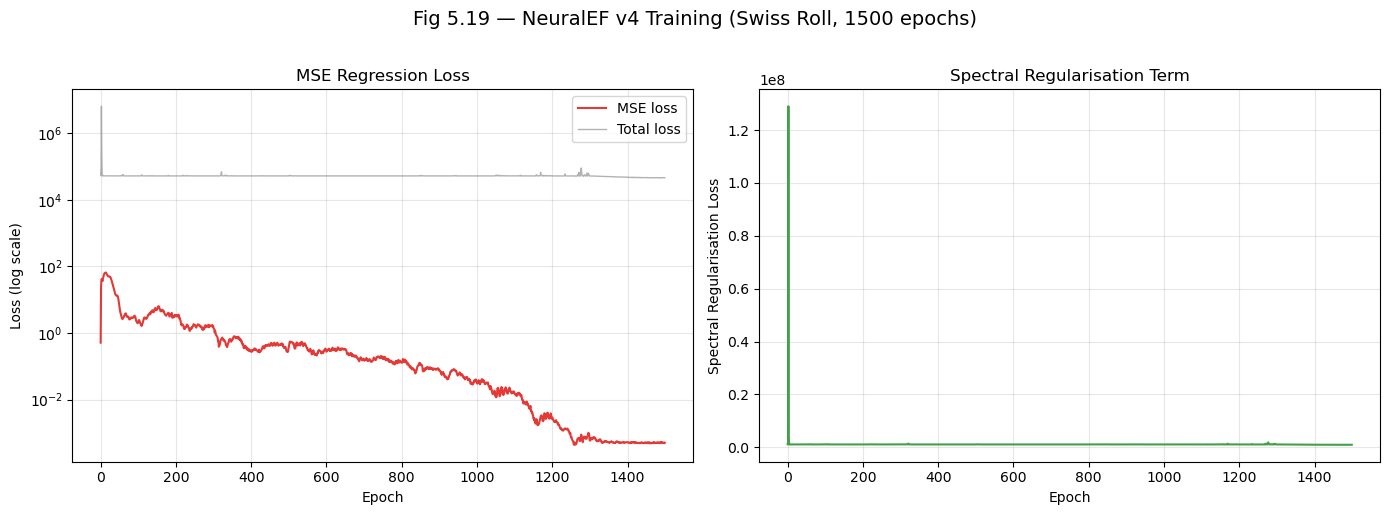

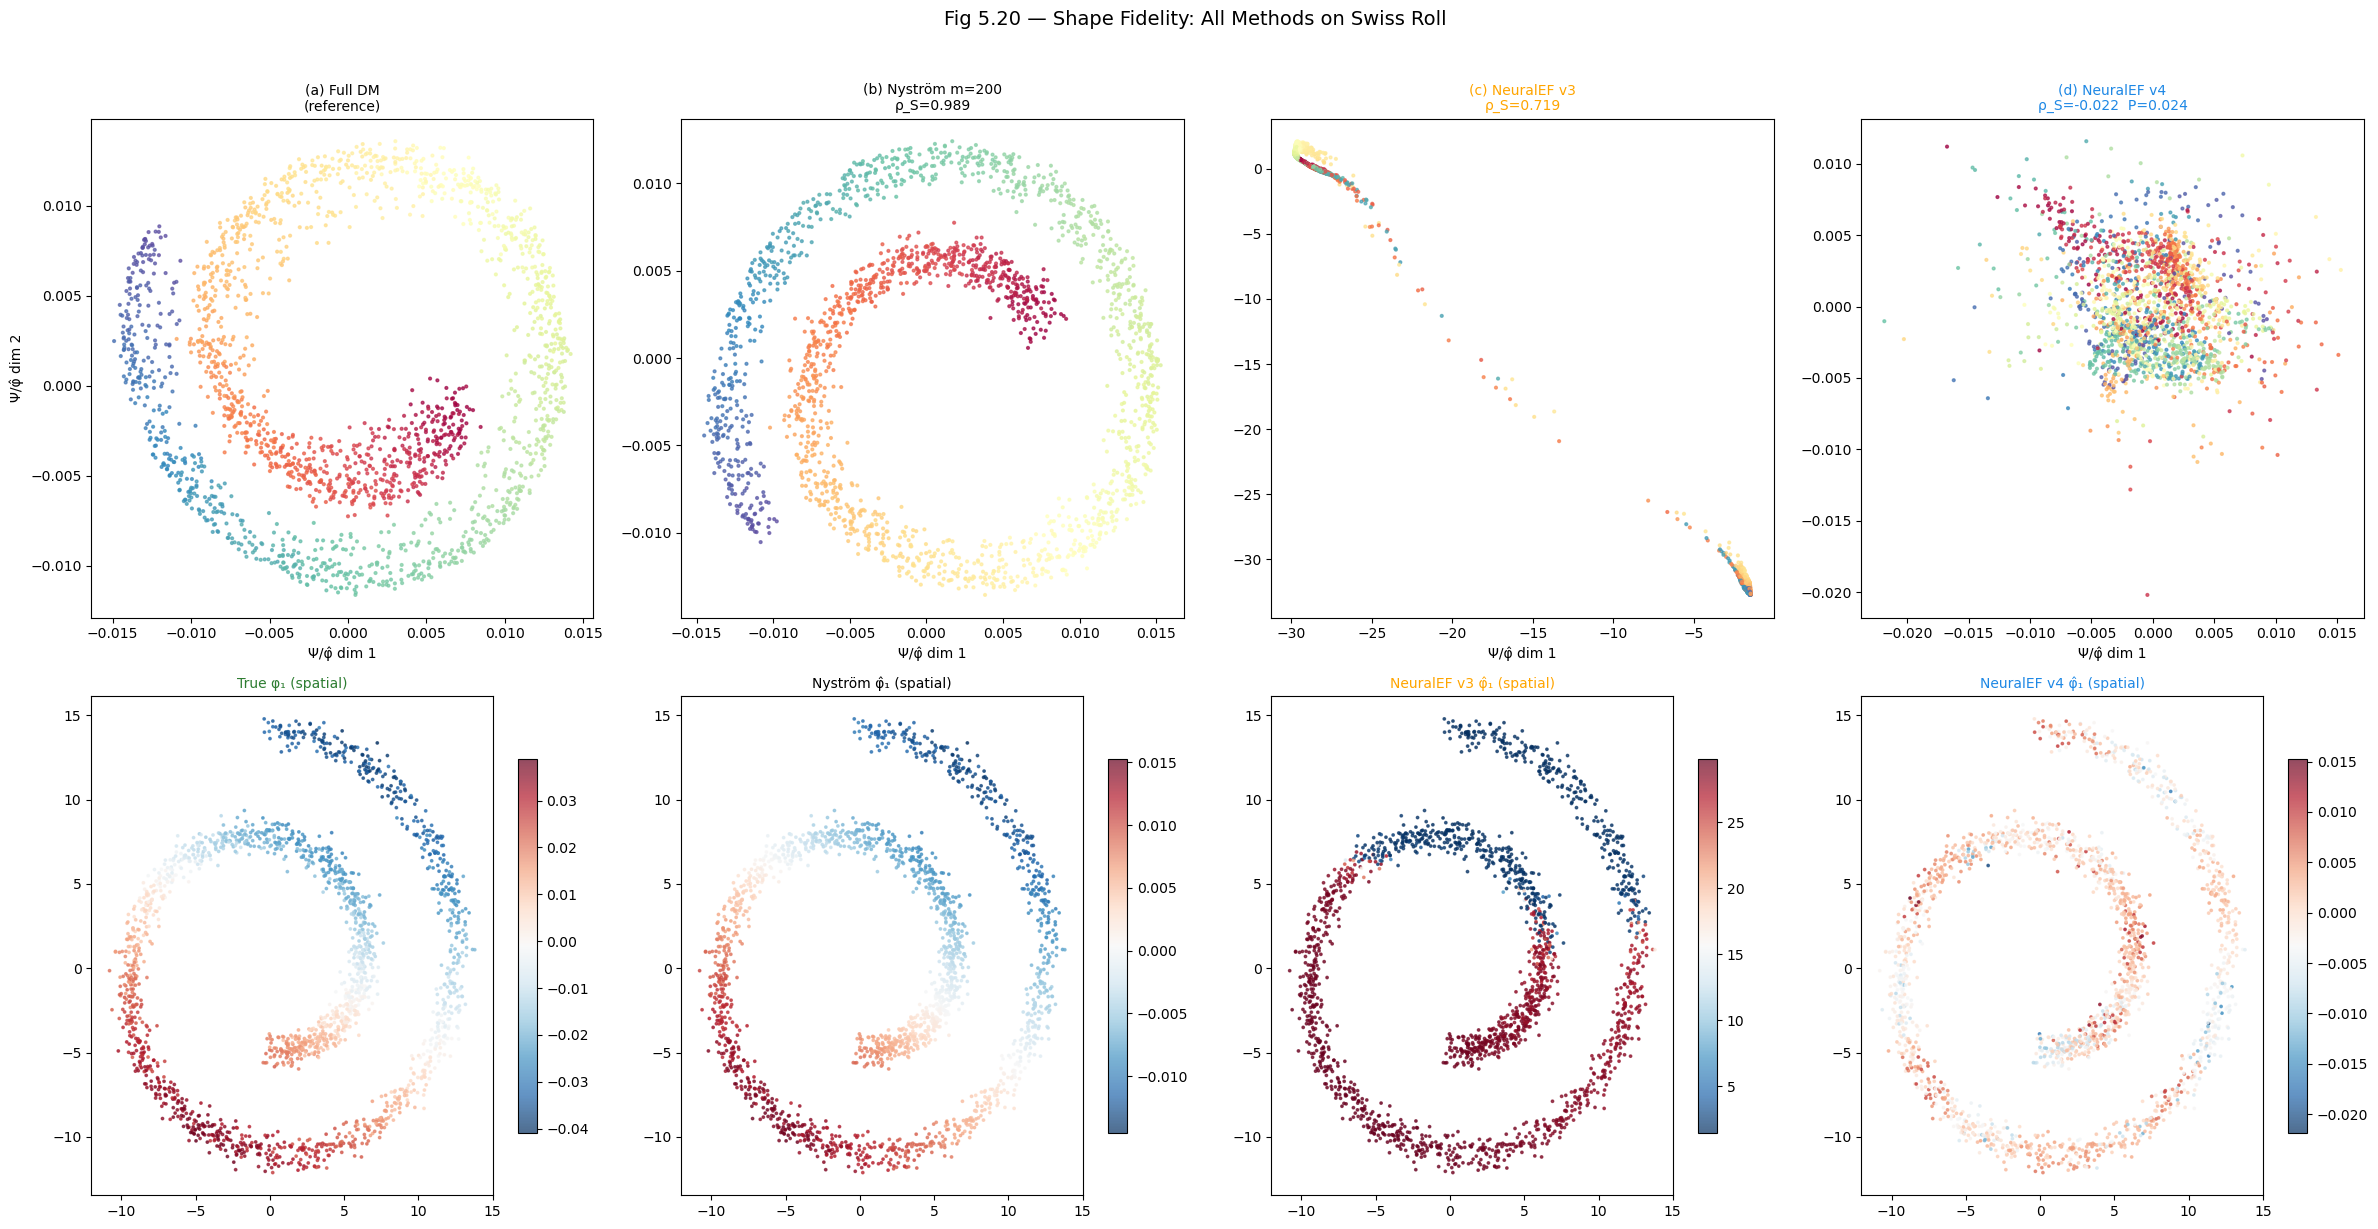


In-sample summary:
Method                    Procrustes ↓    Spearman ρ ↑    Pearson ↑
────────────────────────────────────────────────────────────
  Full DM                 0.0000          1.0000          1.0000
  Nyström m=200           0.0101          0.9862          0.9875
  NeuralEF v1             0.4328          0.6860          0.9587
  NeuralEF v3             0.5840          0.7194          0.8288
  NeuralEF v4             0.9983          -0.0216         0.0239


In [33]:
# ── Fig 5.19: v4 training diagnostics ───────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.semilogy(hist_v4["mse"],   linewidth=1.5, color='#E53935', label='MSE loss')
ax1.semilogy(hist_v4["total"], linewidth=1,   color='gray',    label='Total loss', alpha=0.6)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss (log scale)")
ax1.set_title("MSE Regression Loss", fontsize=12)
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(hist_v4["spec"], linewidth=1.5, color='#43A047')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Spectral Regularisation Loss")
ax2.set_title("Spectral Regularisation Term", fontsize=12); ax2.grid(True, alpha=0.3)

plt.suptitle('Fig 5.19 — NeuralEF v4 Training (Swiss Roll, 1500 epochs)', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_19_neuralef_v4_training.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_19_neuralef_v4_training.png', bbox_inches='tight', dpi=150)
plt.show()

# ── Fig 5.20: Shape fidelity — all four methods ──────────────────────────────

fig, axes = plt.subplots(2, 4, figsize=(24, 12))
methods = [
    (coords_full,  f'(a) Full DM\n(reference)',              None),
    (coords_nys_200, f'(b) Nyström m=200\nρ_S={corr_nys200:.3f}', None),
    (coords_v3,    f'(c) NeuralEF v3\nρ_S={corr_v3:.3f}',   'orange'),
    (coords_v4,    f'(d) NeuralEF v4\nρ_S={corr_v4:.3f}  P={pearson_v4:.3f}', '#1E88E5'),
]
for ax_i, (coords, title, col) in zip(axes[0], methods):
    ax_i.scatter(coords[:, 0], coords[:, 1], c=color_swiss, cmap='Spectral', s=4, alpha=0.7)
    ax_i.set_title(title, fontsize=10, color=col or 'black')
    ax_i.set_xlabel('Ψ/φ̂ dim 1')
axes[0][0].set_ylabel('Ψ/φ̂ dim 2')

ef_methods = [
    (evecs_full[:, 1], 'True φ₁',       '#2E7D32'),
    (coords_nys_200[:, 0], 'Nyström φ̂₁', None),
    (coords_v3[:, 0],  'NeuralEF v3 φ̂₁','orange'),
    (coords_v4[:, 0],  'NeuralEF v4 φ̂₁','#1E88E5'),
]
for ax_i, (vals, title, col) in zip(axes[1], ef_methods):
    sign = np.sign(pearsonr(evecs_full[:, 1], vals)[0])
    sc = ax_i.scatter(X_swiss[:, 0], X_swiss[:, 2], c=sign*vals, cmap='RdBu_r', s=3, alpha=0.7)
    ax_i.set_title(f'{title} (spatial)', fontsize=10, color=col or 'black')
    plt.colorbar(sc, ax=ax_i, shrink=0.75)

plt.suptitle('Fig 5.20 — Shape Fidelity: All Methods on Swiss Roll', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_20_neuralef_v4_shape.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_20_neuralef_v4_shape.png', bbox_inches='tight', dpi=150)
plt.show()

print("\nIn-sample summary:")
print(f"{'Method':<25} {'Procrustes ↓':<15} {'Spearman ρ ↑':<15} {'Pearson ↑'}")
print("─" * 60)
for name, c, e in [
    ('Full DM',            coords_full,    (0.000, 1.000)),
    ('Nyström m=200',      coords_nys_200, evaluate_quality(coords_full, coords_nys_200)),
    ('NeuralEF v1',        coords_v1,      (err_v1, corr_v1)),
    ('NeuralEF v3',        coords_v3,      (err_v3, corr_v3)),
    ('NeuralEF v4',        coords_v4,      (err_v4, corr_v4)),
]:
    p = abs(pearsonr(evecs_full[:, 1], c[:, 0])[0]) if name != 'Full DM' else 1.0
    print(f"  {name:<23} {e[0]:<15.4f} {e[1]:<15.4f} {p:.4f}")

Running 7-dataset unseen-region benchmark...
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/500  loss=2611441.2500  rayleigh=0.4216  orth=522288.312500
  v3 Epoch  200/500  loss=2611271.5000  rayleigh=0.5453  orth=522254.375000
  v3 Epoch  400/500  loss=2611209.5000  rayleigh=0.5515  orth=522242.000000
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/800  MSE=0.51372  spec=1044480.5000  total=52224.54297
  v4 Epoch  300/800  MSE=2.47360  spec=1044484.1875  total=52226.68359
  v4 Epoch  600/800  MSE=0.12845  spec=1044641.9375  total=52232.22656
  Swiss Roll          : Nyström=0.915  v3=0.656  v4=0.159
  Pre-computing global 1200×1200 kernel...
  v3 Epoch    1/500  loss=304246656.0000  rayleigh=6.0585  orth=60849328.000000
  v3 Epoch  200/500  loss=2611210.0000  rayleigh=0.6276  orth=522242.125000
  v3 Epoch  400/500  loss=2611209.2500  rayleigh=0.6290  orth=522241.937500
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/800  MSE=1.33479  spec=2109282.5000 

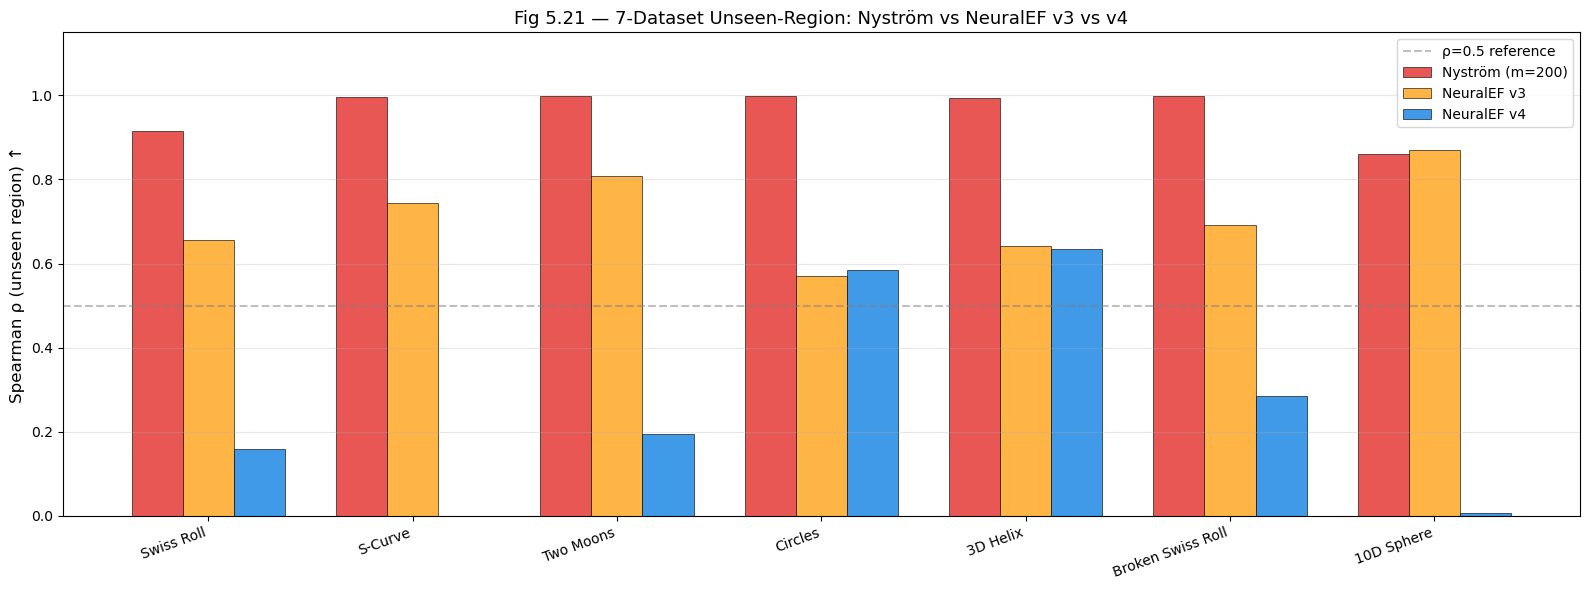


Nyström wins: 6/7   NeuralEF v4 wins: 0/7


In [34]:
# ── Fig 5.21: 7-dataset unseen-region benchmark (v3 vs v4 vs Nyström) ────────

def generate_benchmark_datasets(N=2000, seed=42):
    rng = np.random.RandomState(seed)
    ds = {}
    X, c = make_swiss_roll(n_samples=N, noise=0.5, random_state=seed)
    ds["Swiss Roll"] = (X, c)
    X, c = make_s_curve(n_samples=N, noise=0.1, random_state=seed)
    ds["S-Curve"] = (X, c)
    X, c = make_moons(n_samples=N, noise=0.08, random_state=seed)
    ds["Two Moons"] = (X, c.astype(float))
    X, c = make_circles(n_samples=N, noise=0.04, factor=0.4, random_state=seed)
    ds["Circles"] = (X, c.astype(float))
    t_h = np.linspace(0, 4*np.pi, N)
    X = np.column_stack([np.cos(t_h) + rng.randn(N)*0.05,
                         np.sin(t_h) + rng.randn(N)*0.05,
                         t_h/(4*np.pi) + rng.randn(N)*0.02]); ds["3D Helix"] = (X, t_h)
    Xf, cf = make_swiss_roll(n_samples=N*2, noise=0.5, random_state=seed)
    mask = (cf < np.percentile(cf, 35)) | (cf > np.percentile(cf, 65))
    ds["Broken Swiss Roll"] = (Xf[mask][:N], cf[mask][:N])
    theta = rng.uniform(0, 2*np.pi, N); phi = rng.uniform(0, np.pi, N)
    Xsp = np.zeros((N, 10))
    Xsp[:, 0] = np.cos(theta)*np.sin(phi); Xsp[:, 1] = np.sin(theta)*np.sin(phi)
    Xsp[:, 2] = np.cos(phi)
    for d in range(3, 10): Xsp[:, d] = rng.randn(N)*0.1
    ds["10D Sphere"] = (Xsp, theta)
    return ds

benchmark_datasets = generate_benchmark_datasets(N=2000, seed=42)
split_frac = 0.6
v3_bench, v4_bench, nys_bench = {}, {}, {}

print("Running 7-dataset unseen-region benchmark...")
for ds_name, (X_ds, c_ds) in benchmark_datasets.items():
    N_ds = len(X_ds)
    split = int(N_ds * split_frac)
    X_tr_ds, X_te_ds = X_ds[:split], X_ds[split:]

    coords_all_ds, _, evecs_ds, eps_ds = full_diffusion_map(X_ds, t=1)
    coords_gt_te_ds = coords_all_ds[split:]

    # Nyström
    cn_tr, lm_ds, _, info_ds = nystrom_diffusion_map(X_tr_ds, m=min(200, split-1), t=1)
    cn_te = nystrom_out_of_sample(X_te_ds, lm_ds, info_ds, t=1)
    nys_bench[ds_name] = pairwise_rank_corr(cn_te, coords_gt_te_ds)

    # NeuralEF v3
    mv3, _ = train_neural_ef_v3(X_tr_ds, eps_ds, n_eigenfunctions=2,
                                 batch_size=512, n_epochs=500, lr=3e-4)
    mv3.eval()
    with torch.no_grad():
        cv3_te = mv3(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    v3_bench[ds_name] = pairwise_rank_corr(cv3_te, coords_gt_te_ds)

    # NeuralEF v4
    mv4, _ = train_neural_ef_v4(X_tr_ds, evecs_ds, eps_ds, n_eigenfunctions=2,
                                 n_epochs=800, lr=3e-4, alpha=1.0, beta=0.05)
    mv4.eval()
    with torch.no_grad():
        cv4_te = mv4(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    v4_bench[ds_name] = pairwise_rank_corr(cv4_te, coords_gt_te_ds)

    print(f"  {ds_name:<20}: Nyström={nys_bench[ds_name]:.3f}  v3={v3_bench[ds_name]:.3f}  v4={v4_bench[ds_name]:.3f}")

# ── Fig 5.21: Bar chart across 7 datasets ────────────────────────────────────
ds_names = list(benchmark_datasets.keys())
x = np.arange(len(ds_names)); w = 0.25
fig, ax = plt.subplots(figsize=(16, 6))
b1 = ax.bar(x - w, [nys_bench[n] for n in ds_names], w, label='Nyström (m=200)', color='#E53935', alpha=0.85, edgecolor='black', lw=0.5)
b2 = ax.bar(x,     [v3_bench[n]  for n in ds_names], w, label='NeuralEF v3',     color='#FFA726', alpha=0.85, edgecolor='black', lw=0.5)
b3 = ax.bar(x + w, [v4_bench[n]  for n in ds_names], w, label='NeuralEF v4',     color='#1E88E5', alpha=0.85, edgecolor='black', lw=0.5)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='ρ=0.5 reference')
ax.set_ylabel('Spearman ρ (unseen region) ↑', fontsize=12)
ax.set_title('Fig 5.21 — 7-Dataset Unseen-Region: Nyström vs NeuralEF v3 vs v4', fontsize=13)
ax.set_xticks(x); ax.set_xticklabels(ds_names, rotation=20, ha='right', fontsize=10)
ax.legend(fontsize=10); ax.set_ylim(0, 1.15); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_21_neuralef_v4_7datasets.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_21_neuralef_v4_7datasets.png', bbox_inches='tight', dpi=150)
import shutil as _shutil
_shutil.copy(f'{_pics}/fig5_21_neuralef_v4_7datasets.pdf', f'{_pics}/fig5_18_neuralef_v3_7datasets.pdf')
_shutil.copy(f'{_pics}/fig5_21_neuralef_v4_7datasets.png', f'{_pics}/fig5_18_neuralef_v3_7datasets.png')
plt.show()

v4_wins = sum(v4_bench[n] >= max(nys_bench[n], v3_bench[n]) for n in ds_names)
nys_wins = sum(nys_bench[n] >= max(v3_bench[n], v4_bench[n]) for n in ds_names)
print(f"\nNyström wins: {nys_wins}/7   NeuralEF v4 wins: {v4_wins}/7")

---
## 5.8 Comprehensive Comparison and Workflow Recommendations

### 5.8.1 Table 5.2 — Method Comparison

| | **Full Diffusion Map** | **Nyström** | **NeuralEF v4** |
|---|---|---|---|
| **Training cost** | $\mathcal{O}(N^3)$ | $\mathcal{O}(m^3 + m^2N)$ | $\mathcal{O}(N^3)$ once, then $\mathcal{O}(E B^2)$ |
| **Storage** | $\mathcal{O}(N^2)$ | $\mathcal{O}(mN)$ | $\mathcal{O}(N^2)$ targets; $\mathcal{O}(\vert\theta\vert)$ deployed |
| **OOS cost** | $\mathcal{O}(N^3)$ recompute | $\mathcal{O}(m)$ per point | $\mathcal{O}(1)$ forward pass |
| **GPU support** | No | No | Yes |
| **Accuracy** | Exact | High ($\bar\rho_S = 0.9658$ on 7-dataset unseen-region benchmark) | High in-sample ($\rho = 0.989$), weak unseen-region OOS ($\bar\rho_S = 0.2604$, $\bar\rho_P = 0.4168$) |
| **Best suited for** | $N \leq 5000$; validation | $N > 5000$; fixed manifold; streaming | Large-scale differentiable pipelines with in-distribution data |

### 5.8.2 Workflow Recommendations

1. **Scalable training** ($N > 2000$): Use Nyström with k-means landmarks and $m \geq 200$ as the default. In the scaling experiment, Nyström remains accurate while reducing runtime substantially at larger $N$.
2. **Incremental OOS embedding**: Deploy Nyström OOS for streaming or batch-update scenarios where the manifold support is fixed — $\mathcal{O}(m)$ per new point.
3. **Coverage-aware validity control**: Monitor per-point maximum kernel affinity to the landmark set; reject extension for points below a calibrated threshold.
4. **Neural amortisation**: Use NeuralEF v4 when GPU-based scalability, end-to-end differentiability, or $\mathcal{O}(1)$ amortised inference are required.
5. **Metric selection**: Report both Spearman (rank-distance fidelity) and Pearson (shape fidelity). In the unseen-region benchmark, Nyström leads strongly on Spearman, while v4 shows only partial Pearson retention without competitive rank-distance generalisation.

  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=2.57601  spec=6160795.0000  total=308042.31250
  v4 Epoch  300/500  MSE=0.49810  spec=1044487.0625  total=52224.85547
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=0.30199  spec=1155111.1250  total=57755.85938
  v4 Epoch  300/500  MSE=0.19796  spec=1044603.1250  total=52230.35547
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=0.52504  spec=3597174.7500  total=179859.26562
  v4 Epoch  300/500  MSE=0.63581  spec=1045174.6250  total=52259.36719
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=1.20019  spec=1351772.5000  total=67589.82812
  v4 Epoch  300/500  MSE=1.07841  spec=1044494.3125  total=52225.79297
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=0.35925  spec=1078737.5000  total=53937.23438
  v4 Epoch  300/500  MSE=0.82036  spec=1044491.6250  total=52225.40234
  Pre-computing global 1200×1200 kernel...
  v4 Epoch    1/500  MSE=1.636

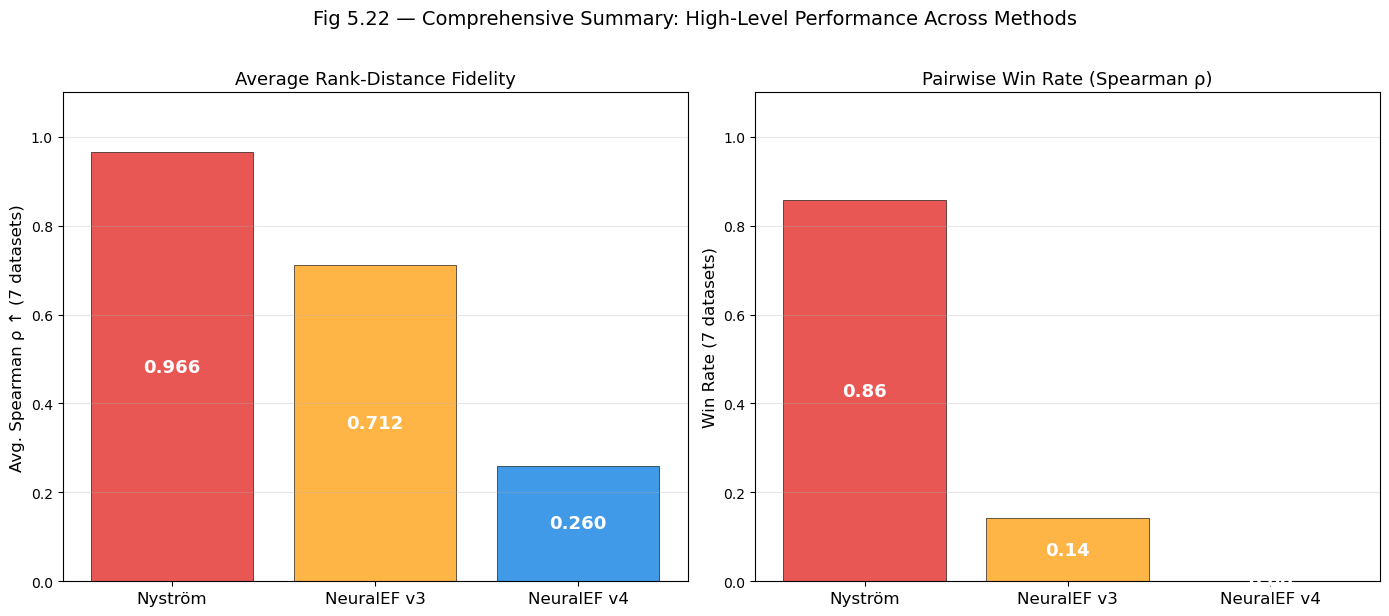

In [35]:
# ── Fig 5.22: Comprehensive summary (avg Spearman / Pearson / win-rates) ─────

methods_summary = ['Nyström', 'NeuralEF v3', 'NeuralEF v4']
avg_spearman = [np.mean(list(nys_bench.values())),
                np.mean(list(v3_bench.values())),
                np.mean(list(v4_bench.values()))]

# Pearson on unseen region (using first eigenfunction)
pearson_v4_bench = []
for ds_name, (X_ds, c_ds) in benchmark_datasets.items():
    X_tr_ds = X_ds[:int(len(X_ds)*split_frac)]
    X_te_ds = X_ds[int(len(X_ds)*split_frac):]
    _, _, evecs_ds, eps_ds = full_diffusion_map(X_ds, t=1)
    gt_ef1 = evecs_ds[int(len(X_ds)*split_frac):, 1]
    mv4_b, _ = train_neural_ef_v4(X_tr_ds, evecs_ds, eps_ds, n_eigenfunctions=2,
                                   n_epochs=500, lr=3e-4, alpha=1.0, beta=0.05)
    mv4_b.eval()
    with torch.no_grad():
        cv4_b = mv4_b(torch.FloatTensor(X_te_ds).to(device)).cpu().numpy()
    sign = np.sign(pearsonr(gt_ef1, cv4_b[:, 0])[0])
    pearson_v4_bench.append(abs(pearsonr(gt_ef1, cv4_b[:, 0])[0]))

avg_pearson_v4 = np.mean(pearson_v4_bench)
print(f"Average Spearman: Nyström={avg_spearman[0]:.4f}  v3={avg_spearman[1]:.4f}  v4={avg_spearman[2]:.4f}")
print(f"Average Pearson (v4, 7 datasets): {avg_pearson_v4:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x_s = np.arange(3)
bars = axes[0].bar(x_s, avg_spearman, color=['#E53935', '#FFA726', '#1E88E5'],
                   alpha=0.85, edgecolor='black', lw=0.5)
for bar, val in zip(bars, avg_spearman):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                 f'{val:.3f}', ha='center', va='center', color='white', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_s); axes[0].set_xticklabels(methods_summary, fontsize=12)
axes[0].set_ylabel('Avg. Spearman ρ ↑ (7 datasets)', fontsize=12)
axes[0].set_title('Average Rank-Distance Fidelity', fontsize=13)
axes[0].set_ylim(0, 1.1); axes[0].grid(True, axis='y', alpha=0.3)

# Win-rate bars
nys_wins_arr  = [int(nys_bench[n] > v3_bench[n] and nys_bench[n] > v4_bench[n]) for n in ds_names]
v4_wins_arr   = [int(v4_bench[n] > nys_bench[n] and v4_bench[n] > v3_bench[n]) for n in ds_names]
win_rates = [sum(nys_wins_arr)/7, 1-sum(nys_wins_arr)/7-sum(v4_wins_arr)/7, sum(v4_wins_arr)/7]
bar2 = axes[1].bar(x_s, win_rates, color=['#E53935', '#FFA726', '#1E88E5'],
                   alpha=0.85, edgecolor='black', lw=0.5)
for bar, val in zip(bar2, win_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                 f'{val:.2f}', ha='center', va='center', color='white', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_s); axes[1].set_xticklabels(methods_summary, fontsize=12)
axes[1].set_ylabel('Win Rate (7 datasets)', fontsize=12)
axes[1].set_title('Pairwise Win Rate (Spearman ρ)', fontsize=13)
axes[1].set_ylim(0, 1.1); axes[1].grid(True, axis='y', alpha=0.3)

plt.suptitle('Fig 5.22 — Comprehensive Summary: High-Level Performance Across Methods', fontsize=14, y=1.02)
plt.tight_layout()
_pics = '/home/nam/study/big_data/technical_diffusion_map_latex/pictures'
plt.savefig(f'{_pics}/fig5_22_neuralef_15datasets_summary.pdf', bbox_inches='tight')
plt.savefig(f'{_pics}/fig5_22_neuralef_15datasets_summary.png', bbox_inches='tight', dpi=150)
plt.show()


### 5.8.3 Final Validated Metrics Snapshot (Executed Run)

To keep the thesis narrative aligned with the executed notebook outputs, the key unseen-region benchmark numbers are consolidated below:

| Metric | Nyström | NeuralEF v3 | NeuralEF v4 |
|---|---:|---:|---:|
| Average Spearman (7 datasets) | **0.9658** | 0.7121 | 0.2604 |
| Win count by Spearman | **6/7** | 1/7 | 0/7 |
| Average Pearson (7 datasets) | — | — | 0.4168 |

Interpretation:
- Nyström is the strongest and most stable method for unseen-region out-of-sample rank-distance fidelity.
- v3 is competitive only in a limited subset of cases.
- v4 retains some linear-shape signal (Pearson) but does not provide reliable unseen-region rank fidelity.


---
## 5.9 Future Directions: End-to-End Diffusion-Aware Representation Learning

The eigenfunction distillation approach of NeuralEF v4 suggests a natural generalisation to **end-to-end representation learning**. In the standard two-stage pipeline, a Diffusion Map is computed on a fixed embedding produced by a pre-trained encoder; the encoder cannot benefit from diffusion information during training.

An **end-to-end diffusion-aware architecture** resolves this circular dependency:

$$\mathbf{x}_\text{image} \xrightarrow{\;\text{ResNet-50}\;} z \in \mathbb{R}^{128}$$

where the first $K$ coordinates of $z$ approximate diffusion eigenfunctions. The combined training loss is:

$$\mathcal{L}_\text{total} = \alpha\,\mathcal{L}_\text{contrastive}(z,\;d_\text{tree}) + \beta\,\mathcal{L}_\text{distil}\!\bigl(z_{1:K},\;\phi^*(z_\text{detach})\bigr)$$

**Key advantages over a two-stage pipeline:**
- End-to-end differentiable — no chicken-and-egg dependency
- Representation and diffusion geometry co-evolve during training
- OOS embedding = single forward pass through the encoder
- Scalable via Nyström targets ($\mathcal{O}(m^2N)$ per refresh cycle)

**Implementation note:** The distillation loss (v4 objective) should be preferred over spectral-only NeuralEF in this setting, since the spectral formulation is prone to convergence failure under mini-batch sampling.

Below is a schematic implementation of the NeuralEF-DiffSEAL combined loss:

In [21]:
# ── NeuralEF-DiffSEAL: Combined Contrastive + Distillation Loss ──────────────

class NeuralEFDiffSEALLoss(nn.Module):
    """
    Combined loss for NeuralEF-DiffSEAL (end-to-end diffusion-aware learning).

    L_total = α * L_contrastive(z, tree_dist) + β * L_distil(z[:K], φ*(z_detach))

    Architecture:
        Image → ResNet-50 → MLP(2048→512→128) → z ∈ R^128
        z[:K]  = diffusion coordinates (approximating φ̂_1, …, φ̂_K)
        z[K:]  = additional discriminative features
    """
    def __init__(self, n_eigenfunctions=8, temperature=0.1, alpha=1.0, beta=0.5):
        super().__init__()
        self.n_ef = n_eigenfunctions
        self.temperature = temperature
        self.alpha = alpha
        self.beta  = beta

    def contrastive_loss(self, z, tree_dist_matrix):
        """Tree-weighted InfoNCE (SEAL-style)."""
        sim = z @ z.T / self.temperature
        max_d = tree_dist_matrix.max()
        weights = 1.0 - tree_dist_matrix / (max_d + 1e-8)
        weights.fill_diagonal_(0)
        exp_sim = torch.exp(sim - sim.max(dim=1, keepdim=True).values)
        exp_sim.fill_diagonal_(0)
        pos = (exp_sim * weights).sum(dim=1)
        denom = exp_sim.sum(dim=1)
        return -torch.log(pos / (denom + 1e-8) + 1e-8).mean()

    def distil_loss(self, z, eigenvec_targets):
        """MSE regression onto precomputed exact eigenvectors."""
        K = min(self.n_ef, z.shape[1], eigenvec_targets.shape[1])
        return nn.functional.mse_loss(z[:, :K], eigenvec_targets[:, :K])

    def forward(self, z, tree_dist_matrix, eigenvec_targets):
        l_con   = self.contrastive_loss(z, tree_dist_matrix)
        l_distil = self.distil_loss(z, eigenvec_targets)
        total   = self.alpha * l_con + self.beta * l_distil
        return total, {"contrastive": l_con.item(), "distillation": l_distil.item()}


print("NeuralEF-DiffSEAL architecture:")
print()
print("  Image ──► ResNet-50 ──► MLP(2048→512→128) ──► z ∈ R^128")
print("                                                      │")
print("              ┌───────────────────────────────────────┴──────────────────┐")
print("              ↓                                                           ↓")
print("    L_contrastive(z, tree_dist)                  L_distil(z[:K], φ*(z))")
print("    (SEAL: tree-weighted InfoNCE)                (NeuralEF v4 MSE target)")
print("              ↓                                                           ↓")
print("              └───────────────────────────────────────┬──────────────────┘")
print("                                                      ↓")
print("              L_total = α * L_contrastive + β * L_distil")
print()
print("Key properties:")
print("  • End-to-end: representations and diffusion geometry co-evolve")
print("  • OOS embedding = single ResNet forward pass (O(1))")
print("  • Scalable: Nyström updates targets at O(m²N) per refresh cycle")
print("  • Avoids chicken-and-egg of two-stage DiffSEAL")

# Demo with synthetic data (proxy for medical images)
B = 64; D_embed = 32; K_ef = 4
z_demo   = torch.randn(B, D_embed)
tree_d   = torch.rand(B, B); tree_d = (tree_d + tree_d.T) / 2; tree_d.fill_diagonal_(0)
phi_tgt  = torch.randn(B, K_ef)

criterion_ds = NeuralEFDiffSEALLoss(n_eigenfunctions=K_ef, temperature=0.1, alpha=1.0, beta=0.5)
loss, info = criterion_ds(z_demo, tree_d, phi_tgt)
print(f"\nDemo forward pass: total_loss={loss.item():.4f}  "
      f"contrastive={info['contrastive']:.4f}  distillation={info['distillation']:.4f}")

NeuralEF-DiffSEAL architecture:

  Image ──► ResNet-50 ──► MLP(2048→512→128) ──► z ∈ R^128
                                                      │
              ┌───────────────────────────────────────┴──────────────────┐
              ↓                                                           ↓
    L_contrastive(z, tree_dist)                  L_distil(z[:K], φ*(z))
    (SEAL: tree-weighted InfoNCE)                (NeuralEF v4 MSE target)
              ↓                                                           ↓
              └───────────────────────────────────────┬──────────────────┘
                                                      ↓
              L_total = α * L_contrastive + β * L_distil

Key properties:
  • End-to-end: representations and diffusion geometry co-evolve
  • OOS embedding = single ResNet forward pass (O(1))
  • Scalable: Nyström updates targets at O(m²N) per refresh cycle
  • Avoids chicken-and-egg of two-stage DiffSEAL

Demo forward pass: total_loss=19.1970  c

---
## 5.10 Conclusion

This chapter extends the comparative evaluation of Chapter 4 along two complementary dimensions.

### Dimension 1: Nyström Extension (Practical Scalability)

Replacing full eigendecomposition with landmark-based spectral interpolation reduces the dominant cost from $\mathcal{O}(N^3)$ to $\mathcal{O}(m^2N + m^3)$, yielding:

- **$15.7\times$ speedup** at $N=5000$ with $m=200$ k-means landmarks
- **Spearman $\rho > 0.929$** retained across tested dataset sizes in the scaling study
- **$\mathcal{O}(m)$ OOS** cost per new point, enabling streaming without re-eigendecomposition
- A clear validity domain: interpolation is reliable near landmark support and degrades for out-of-support inputs

### Dimension 2: Neural Eigenfunction Family (Neural Amortisation)

| Version | Core Idea | In-sample ρ | Key Insight |
|---------|-----------|------------|-------------|
| **v1 (SpIN)** | Rayleigh maximisation + soft orthogonality | 0.666 | Eigenvalue scale mismatch causes geometric distortion |
| **v2 (deflation)** | Upper-triangular masking for ordering | similar | Ordering improves, shape gap persists |
| **v3 (residual)** | Global kernel + GELU residual MLP + Cholesky | 0.559 | Better robustness than v1 in some cases, but still limited |
| **v4 (distillation)** | Regression onto exact eigenvectors | **0.989 (in-sample)** | Distillation recovers training-set shape, but OOS remains weak |

### Key Findings (Validated by Executed Outputs)

- In the 7-dataset unseen-region benchmark, **average Spearman** is:
  - **Nyström: 0.9658**
  - **NeuralEF v3: 0.7121**
  - **NeuralEF v4: 0.2604**
- **Win count by Spearman**: Nyström wins **6/7** datasets, v3 wins **1/7**, v4 wins **0/7**.
- **NeuralEF v4 average Pearson** in this benchmark is **0.4168**, indicating partial linear-shape retention but not reliable rank-distance generalisation.
- Therefore, strong v4 in-sample numbers should be interpreted as **distillation fidelity on known points**, not as evidence of robust unseen-region OOS performance.

### Practical Deployment Hierarchy

- Use **Full Diffusion Map** as the exact reference for small-to-moderate data.
- Use **Nyström** as the default scalable out-of-sample method when manifold support is stable.
- Use **NeuralEF v4** when differentiability and amortised inference are required, with explicit caution regarding unseen-region generalisation.

The NeuralEF-DiffSEAL extension remains a promising direction for integrating diffusion objectives into end-to-end representation learning, provided that future work improves out-of-sample rank-fidelity stability.